# Лабораторная работа №2. Классификация. Нейронные сети

## 1. Введение

**Цель работы** – изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями на основе библиотеки TensorFlow (Keras) и средством визуализации процесса обучения TensorBoard.

**Задачи работы:**

1. Выбрать и подготовить набор данных для задачи бинарной классификации: провести разведочный анализ признаков, обработать аномальные значения, выполнить стандартизацию.
2. Разделить данные на обучающую и тестовую выборки (функция `train_test_split`, соотношение 80/20, стратификация по классу, `random_state=42`).
3. Построить классификаторы пятью методами:
   1. наивный байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
   2. дерево решений (Decision Tree);
   3. линейный дискриминантный анализ (Linear Discriminant Analysis, LDA);
   4. метод опорных векторов (Support Vector Machines, SVM);
   5. метод k ближайших соседей (k-Nearest Neighbors, kNN).
4. Сравнить качество классификаторов по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.
5. Настроить гиперпараметры каждого метода (кросс-валидация, `GridSearchCV`, кривые валидации) и исследовать влияние параметров на качество классификации.
6. Построить нейронную сеть на TensorFlow, исследовать влияние числа эпох, размера батча, числа слоёв и нейронов, функций активации на качество модели и визуализировать процесс обучения в TensorBoard.
7. Провести сравнительный анализ и обосновать выбор наилучшего подхода для рассматриваемого набора данных.

Для воспроизводимости результатов все источники случайности зафиксированы значением `SEED = 42`: разбиение выборки, формирование фолдов кросс-валидации, построение деревьев, инициализация весов нейронной сети. Для TensorFlow дополнительно включён детерминированный режим вычислений (`enable_op_determinism`). Повторный запуск ноутбука воспроизводит все метрики без изменений.

## 2. Выбор и подготовка датасета

В работе используется набор данных [Credit Risk Benchmark Dataset](https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset). Он представляет собой сбалансированную выборку сведений о заёмщиках банка и по структуре признаков совпадает с известным набором Give Me Some Credit. Набор содержит 16 714 наблюдений, 10 признаков и бинарную целевую переменную – факт серьёзной просрочки (90 дней и более) в течение двух лет.

Решаемая задача – бинарная классификация: по финансовому профилю клиента требуется предсказать наступление дефолта. Это типичная постановка задачи кредитного скоринга.

Описание столбцов:

| Признак | Исходное имя | Содержание | Тип |
|---|---|---|---|
| Использование лимита | `rev_util` | Доля использованного лимита по кредитным картам и кредитным линиям (задолженность / лимит) | Непрерывный |
| Возраст | `age` | Возраст заёмщика, лет | Числовой |
| Просрочки 30–59 дн. | `late_30_59` | Число просрочек длительностью 30–59 дней за два года | Счётчик |
| Долговая нагрузка | `debt_ratio` | Отношение ежемесячных платежей по долгам к месячному доходу | Непрерывный |
| Месячный доход | `monthly_inc` | Месячный доход, долл. | Числовой |
| Открытые кредиты | `open_credit` | Число открытых кредитов и кредитных линий | Счётчик |
| Просрочки 90+ дн. | `late_90` | Число просрочек длительностью 90 дней и более | Счётчик |
| Ипотечные кредиты | `real_estate` | Число ипотечных кредитов и кредитов под залог недвижимости | Счётчик |
| Просрочки 60–89 дн. | `late_60_89` | Число просрочек длительностью 60–89 дней | Счётчик |
| Иждивенцы | `dependents` | Число иждивенцев в семье | Счётчик |
| Дефолт | `dlq_2yrs` | 1 – просрочка 90 дней и более в течение двух лет, 0 – отсутствие такой просрочки | Целевая переменная |

In [1]:
%matplotlib inline
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # скрыть служебные сообщения TensorFlow
import time
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, validation_curve,
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

RU_NAMES = {
    "rev_util": "Использование лимита",
    "age": "Возраст",
    "late_30_59": "Просрочки 30–59 дн.",
    "debt_ratio": "Долговая нагрузка",
    "monthly_inc": "Месячный доход",
    "open_credit": "Открытые кредиты",
    "late_90": "Просрочки 90+ дн.",
    "real_estate": "Ипотечные кредиты",
    "late_60_89": "Просрочки 60–89 дн.",
    "dependents": "Иждивенцы",
    "dlq_2yrs": "Дефолт",
}
TARGET = "Дефолт"

df = pd.read_csv("data/credit_risk.csv").rename(columns=RU_NAMES)

print(f"Размерность: {df.shape[0]} заёмщиков, {df.shape[1]} столбцов (10 признаков + цель)")
print("Первые 5 строк:")
display(df.head())
print("Пропущенные значения:")
display(df.isnull().sum().rename("Пропуски").to_frame().T)
print(f"Полных дубликатов строк: {df.duplicated().sum()}")
print("Баланс классов:")
display(pd.DataFrame({
    "Заёмщиков": df[TARGET].value_counts().sort_index(),
    "Доля, %": (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index={0: "0 – нет просрочки", 1: "1 – дефолт"}))

Размерность: 16714 заёмщиков, 11 столбцов (10 признаков + цель)
Первые 5 строк:


,Использование лимита,Возраст,Просрочки 30–59 дн.,Долговая нагрузка,Месячный доход,Открытые кредиты,Просрочки 90+ дн.,Ипотечные кредиты,Просрочки 60–89 дн.,Иждивенцы,Дефолт
0,0.006999,38.0,0.0,0.302150,5440.0,4.0,0.0,1.0,0.0,3.0,0
1,0.704592,63.0,0.0,0.471441,8000.0,9.0,0.0,1.0,0.0,0.0,0
2,0.063113,57.0,0.0,0.068586,5000.0,17.0,0.0,0.0,0.0,0.0,0
3,0.368397,68.0,0.0,0.296273,6250.0,16.0,0.0,2.0,0.0,0.0,0
4,1.000000,34.0,1.0,0.000000,3500.0,0.0,0.0,0.0,0.0,1.0,0


Пропущенные значения:


,Использование лимита,Возраст,Просрочки 30–59 дн.,Долговая нагрузка,Месячный доход,Открытые кредиты,Просрочки 90+ дн.,Ипотечные кредиты,Просрочки 60–89 дн.,Иждивенцы,Дефолт
Пропуски,0,0,0,0,0,0,0,0,0,0,0


Полных дубликатов строк: 2
Баланс классов:


,Заёмщиков,"Доля, %"
Дефолт,,
0 – нет просрочки,8357,50.0
1 – дефолт,8357,50.0


### Пояснение к загрузке данных

- Объём выборки: 16 714 заёмщиков, 10 признаков и целевая переменная «Дефолт».
- Пропуски в явном виде (`NaN`) отсутствуют. Однако, как показано ниже, часть пропущенных значений закодирована служебными числами 96 и 98, и их необходимо обработать отдельно.
- Дубликаты: обнаружено 2 полностью совпадающие строки. Они удаляются до разбиения выборки, чтобы одно и то же наблюдение не оказалось одновременно в обучающей и тестовой выборках.
- Баланс классов: классы сбалансированы точно в соотношении 50/50 (по 8 357 заёмщиков). Это свойство выбранного эталонного набора: в исходных данных Give Me Some Credit доля дефолтов составляет около 7%, а здесь выборка уравновешена. Следовательно, метрика Accuracy корректно отражает качество модели, а тривиальный классификатор, не использующий признаки, обеспечивает точность 50%.

In [2]:
feature_names = [c for c in df.columns if c != TARGET]
LATE = ["Просрочки 30–59 дн.", "Просрочки 60–89 дн.", "Просрочки 90+ дн."]

stats_df = df[feature_names].describe().T
stats_df["Медиана"] = df[feature_names].median()
stats_df["Коэффициент асимметрии"] = df[feature_names].skew()
stats_df = stats_df.rename(columns={"mean": "Среднее", "std": "Станд. откл.", "min": "Минимум", "max": "Максимум",
                                    "25%": "Q1", "75%": "Q3"})
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
display(stats_df[["Среднее", "Станд. откл.", "Медиана", "Q1", "Q3", "Минимум", "Максимум",
                  "Коэффициент асимметрии"]].round(3))

code_mask = df[LATE[0]] >= 90
print("Аномалии в данных:")
anom = pd.DataFrame({
    "Строк": [
        int(code_mask.sum()),
        int((df["Использование лимита"] > 1).sum()),
        int((df["Использование лимита"] > 2).sum()),
        int((df["Месячный доход"] <= 1).sum()),
        int((df["Долговая нагрузка"] > 10).sum()),
    ],
    "Доля дефолтов, %": [
        df.loc[code_mask, TARGET].mean() * 100,
        df.loc[df["Использование лимита"] > 1, TARGET].mean() * 100,
        df.loc[df["Использование лимита"] > 2, TARGET].mean() * 100,
        df.loc[df["Месячный доход"] <= 1, TARGET].mean() * 100,
        df.loc[df["Долговая нагрузка"] > 10, TARGET].mean() * 100,
    ],
}, index=[
    "Коды 96/98 в счётчиках просрочек",
    "Использование лимита > 1 (превышение лимита)",
    "Использование лимита > 2 (ошибки записи)",
    "Месячный доход ≤ 1 $ (доход не указан)",
    "Долговая нагрузка > 10",
])
display(anom.round(1))
print("Значения счётчиков просрочек у строк с кодами:")
display(df.loc[code_mask, LATE].drop_duplicates())

ОПИСАТЕЛЬНАЯ СТАТИСТИКА


,Среднее,Станд. откл.,Медиана,Q1,Q3,Минимум,Максимум,Коэффициент асимметрии
Использование лимита,4.800,204.062,0.443,0.082,0.927,0.0,22000.0,82.391
Возраст,48.799,13.906,48.000,38.000,58.000,21.0,101.0,0.361
Просрочки 30–59 дн.,1.110,7.173,0.000,0.000,1.000,0.0,98.0,13.104
Долговая нагрузка,30.980,719.695,0.322,0.156,0.533,0.0,61106.5,61.240
Месячный доход,6118.120,5931.842,5000.000,3128.500,7573.000,0.0,250000.0,11.951
Открытые кредиты,8.504,5.371,8.000,5.000,11.000,0.0,57.0,1.168
Просрочки 90+ дн.,0.864,7.168,0.000,0.000,0.000,0.0,98.0,13.236
Ипотечные кредиты,1.047,1.273,1.000,0.000,2.000,0.0,29.0,3.573
Просрочки 60–89 дн.,0.734,7.139,0.000,0.000,0.000,0.0,98.0,13.444
Иждивенцы,0.944,1.199,0.000,0.000,2.000,0.0,8.0,1.280


Аномалии в данных:


,Строк,"Доля дефолтов, %"
Коды 96/98 в счётчиках просрочек,89,94.4
Использование лимита > 1 (превышение лимита),1166,88.3
Использование лимита > 2 (ошибки записи),61,75.4
Месячный доход ≤ 1 $ (доход не указан),248,33.5
Долговая нагрузка > 10,241,35.3


Значения счётчиков просрочек у строк с кодами:


,Просрочки 30–59 дн.,Просрочки 60–89 дн.,Просрочки 90+ дн.
765,98.0,98.0,98.0
12211,96.0,96.0,96.0


### Пояснение к описательной статистике

Сопоставление среднего значения и медианы указывает на наличие грубых выбросов:

- «Использование лимита»: медиана 0.44, третий квартиль 0.93, однако среднее равно 4.80, а максимум – 22 000 (коэффициент асимметрии +82). Признак представляет собой долю использованного лимита, поэтому значения, многократно превышающие единицу, следует считать ошибками записи. Вместе с тем умеренное превышение лимита (значения от 1 до 2) содержательно: среди 1 166 заёмщиков с использованием лимита больше 1 доля дефолтов составляет 88%.
- «Долговая нагрузка»: медиана 0.32, максимум 61 106 (асимметрия +61). Аномально большие значения соответствуют заёмщикам, не указавшим доход (не более 1 долл.): для них в поле записан абсолютный размер долга, а не отношение. Таких заёмщиков 248, доля дефолтов среди них – 33.5%, что ниже среднего.
- Счётчики просрочек: у 89 заёмщиков во всех трёх полях записаны значения 96 или 98. Это не число просрочек, а служебные коды отсутствия данных. При этом признак информативен: доля дефолтов среди таких строк составляет 94.4%.
- «Месячный доход»: медиана 5 000 долл., максимум 250 000 долл., асимметрия +12.
- «Возраст» распределён практически симметрично (медиана 48 лет, асимметрия +0.36).

На основании этого анализа определён порядок предобработки: замена кодов 96/98 пропусками с последующим заполнением медианой и введением отдельного признака-индикатора; ограничение выбросов по 99-му перцентилю; логарифмирование признаков с сильной асимметрией; введение индикатора отсутствия дохода; стандартизация.

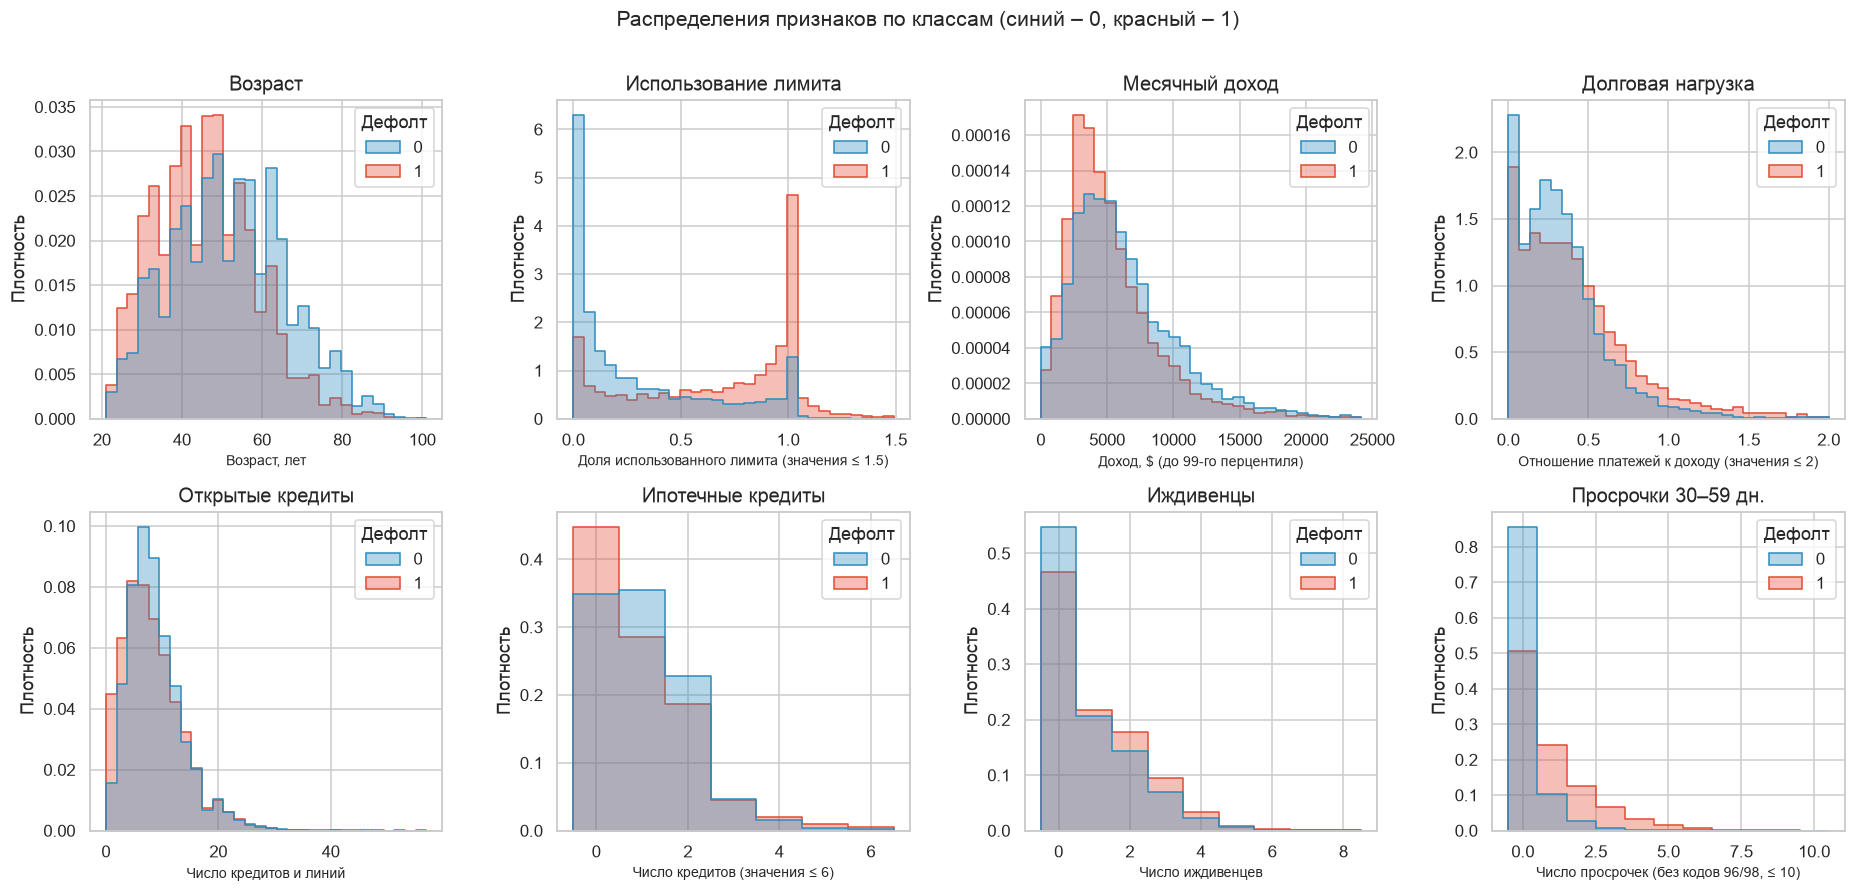

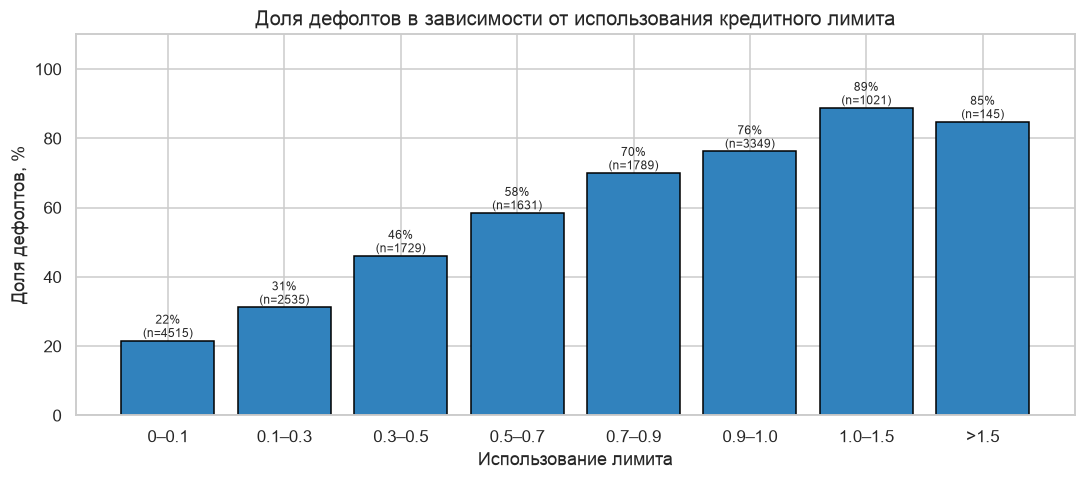

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
plot_specs = [
    ("Возраст", "Возраст, лет", None),
    ("Использование лимита", "Доля использованного лимита (значения ≤ 1.5)", 1.5),
    ("Месячный доход", "Доход, $ (до 99-го перцентиля)", df["Месячный доход"].quantile(0.99)),
    ("Долговая нагрузка", "Отношение платежей к доходу (значения ≤ 2)", 2.0),
    ("Открытые кредиты", "Число кредитов и линий", None),
    ("Ипотечные кредиты", "Число кредитов (значения ≤ 6)", 6),
    ("Иждивенцы", "Число иждивенцев", None),
    ("Просрочки 30–59 дн.", "Число просрочек (без кодов 96/98, ≤ 10)", 10),
]
colors = {0: "#2b8cbe", 1: "#e34a33"}
for ax, (col, xlabel, cap) in zip(axes.ravel(), plot_specs):
    data = df[[col, TARGET]].copy()
    if col in LATE:
        data = data[data[col] < 90]
    if cap is not None:
        data = data[data[col] <= cap]
    discrete = data[col].nunique() <= 15
    sns.histplot(data=data, x=col, hue=TARGET, ax=ax, bins=30, discrete=discrete,
                 stat="density", common_norm=False, element="step", palette=colors, alpha=0.35)
    ax.set_title(col)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("Плотность")
    leg = ax.get_legend()
    if leg is not None:
        leg.set_title("Дефолт")
plt.suptitle("Распределения признаков по классам (синий – 0, красный – 1)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = pd.cut(df["Использование лимита"], [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.5, np.inf],
              labels=["0–0.1", "0.1–0.3", "0.3–0.5", "0.5–0.7", "0.7–0.9", "0.9–1.0", "1.0–1.5", ">1.5"])
rate = df.groupby(bins, observed=True)[TARGET].agg(["mean", "count"])
bars = ax.bar(rate.index.astype(str), rate["mean"] * 100, color="#3182bd", edgecolor="black")
ax.bar_label(bars, labels=[f"{m*100:.0f}%\n(n={n})" for m, n in zip(rate["mean"], rate["count"])], fontsize=8)
ax.set_ylim(0, 110)
ax.set_xlabel("Использование лимита")
ax.set_ylabel("Доля дефолтов, %")
ax.set_title("Доля дефолтов в зависимости от использования кредитного лимита")
plt.tight_layout()
plt.show()

### Пояснение к графикам распределения

Гистограммы построены отдельно для каждого класса и нормированы на его объём, что позволяет сравнивать форму распределений:

- «Использование лимита» – наиболее информативный признак. У надёжных заёмщиков распределение сосредоточено около нуля (кредитный лимит практически не используется), у заёмщиков с дефолтом наблюдается пик около 1.0 (лимит исчерпан). Столбчатая диаграмма показывает монотонный рост доли дефолтов по мере увеличения использования лимита.
- «Просрочки 30–59 дн.»: около 85% надёжных заёмщиков не имеют просрочек, тогда как среди заёмщиков с дефолтом таких лишь около половины.
- «Возраст»: заёмщики с дефолтом в среднем моложе – их распределение смещено влево; в возрасте старше 60 лет преобладают надёжные заёмщики.
- «Месячный доход» у заёмщиков с дефолтом несколько ниже, а «Долговая нагрузка» несколько выше; однако распределения классов в значительной степени перекрываются.
- «Открытые кредиты», «Ипотечные кредиты», «Иждивенцы» – дискретные признаки с правосторонней асимметрией; различия между классами по ним невелики.

Таким образом, классы существенно перекрываются, и безошибочное разделение невозможно. Основную информацию о риске дефолта несут использование кредитного лимита и история просрочек.

Связь признаков с целевой переменной:


,Пирсон,Спирмен
Возраст,-0.211,-0.206
Месячный доход,-0.082,-0.136
Открытые кредиты,-0.049,-0.068
Ипотечные кредиты,-0.004,-0.066
Иждивенцы,0.087,0.090
Долговая нагрузка,-0.013,0.103
Просрочки 60–89 дн.,0.089,0.331
Просрочки 90+ дн.,0.106,0.386
Просрочки 30–59 дн.,0.118,0.393
Использование лимита,-0.006,0.463


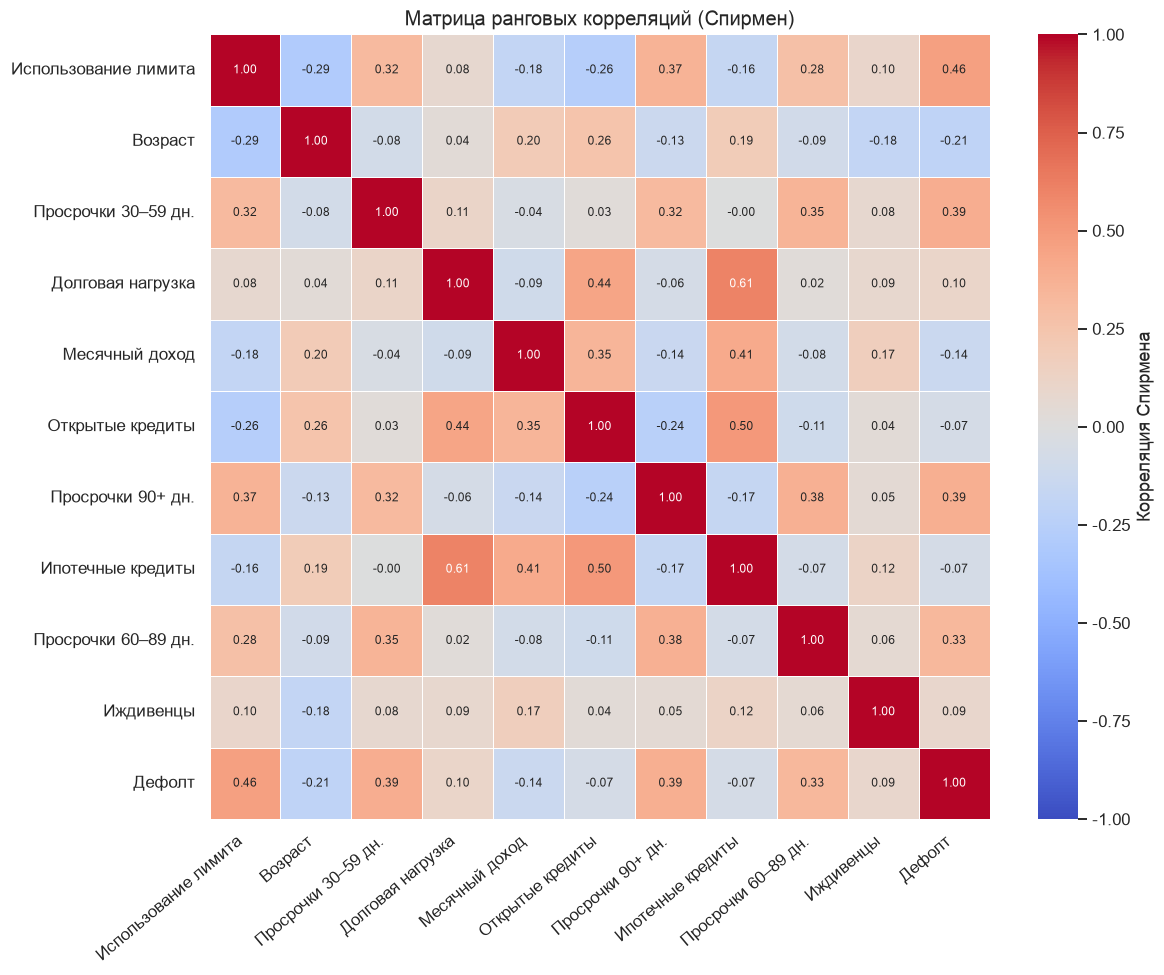

In [4]:
corr_raw = df.corr(numeric_only=True, method="pearson")[TARGET].drop(TARGET)
corr_spear = df.corr(numeric_only=True, method="spearman")[TARGET].drop(TARGET)
print("Связь признаков с целевой переменной:")
display(pd.DataFrame({"Пирсон": corr_raw, "Спирмен": corr_spear}).sort_values("Спирмен").round(3))

plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.4, annot_kws={"size": 8},
            cbar_kws={"label": "Корреляция Спирмена"})
plt.title("Матрица ранговых корреляций (Спирмен)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

### Пояснение к корреляциям

Коэффициент корреляции Пирсона в данном случае неинформативен: для признака «Использование лимита» он равен −0.006, хотя по графикам этот признак разделяет классы лучше остальных. Причина – выбросы (до 22 000), к которым линейная корреляция крайне чувствительна. Ранговый коэффициент корреляции Спирмена устойчив к выбросам и отражает фактическую связь:

- «Использование лимита»: $\rho = +0.46$ – наиболее сильная связь с дефолтом;
- «Просрочки 30–59 дн.», «Просрочки 90+ дн.», «Просрочки 60–89 дн.»: $\rho = +0.39$, $+0.39$ и $+0.33$ соответственно;
- «Возраст»: $\rho = -0.21$ – с увеличением возраста риск снижается;
- «Месячный доход»: $\rho = -0.14$; «Долговая нагрузка»: $\rho = +0.10$; «Иждивенцы»: $\rho = +0.09$;
- «Открытые кредиты» и «Ипотечные кредиты» практически не связаны с целевой переменной ($|\rho| < 0.07$).

Наиболее тесно связаны между собой три счётчика просрочек (они отражают одно явление разной степени тяжести), а также пара «Открытые кредиты» – «Ипотечные кредиты». Сильной мультиколлинеарности не выявлено, поэтому все признаки сохраняются.

## 3. Предобработка и разбиение выборки

In [5]:
df_clean = df.drop_duplicates().reset_index(drop=True)
X = df_clean[feature_names]
y = df_clean[TARGET]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

LOG_COLS = ["Долговая нагрузка", "Месячный доход", "Ипотечные кредиты"] + LATE


def fit_prep(X_tr):
    """Параметры предобработки считаются только по обучающей выборке."""
    ok = X_tr[LATE[0]] < 90
    return {
        "late_median": X_tr.loc[ok, LATE].median(),
        "rev_cap": X_tr["Использование лимита"].quantile(0.99),
        "debt_cap": X_tr["Долговая нагрузка"].quantile(0.99),
        "inc_cap": X_tr["Месячный доход"].quantile(0.99),
    }


def apply_prep(X_in, p):
    Xp = X_in.copy()
    Xp["Код 96/98"] = (Xp[LATE[0]] >= 90).astype(int)
    Xp["Доход не указан"] = (Xp["Месячный доход"] <= 1).astype(int)
    for c in LATE:                                    # служебные коды -> пропуск -> медиана train
        Xp[c] = Xp[c].where(Xp[c] < 90, np.nan).fillna(p["late_median"][c])
    Xp["Использование лимита"] = Xp["Использование лимита"].clip(upper=p["rev_cap"])
    Xp["Долговая нагрузка"] = Xp["Долговая нагрузка"].clip(upper=p["debt_cap"])
    Xp["Месячный доход"] = Xp["Месячный доход"].clip(upper=p["inc_cap"])
    for c in LOG_COLS:
        Xp[c] = np.log1p(Xp[c])
    return Xp


prep_params = fit_prep(X_train_raw)
X_train_p = apply_prep(X_train_raw, prep_params)
X_test_p = apply_prep(X_test_raw, prep_params)
final_features = list(X_train_p.columns)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_p), columns=final_features, index=X_train_p.index)
X_test = pd.DataFrame(scaler.transform(X_test_p), columns=final_features, index=X_test_p.index)

mm = MinMaxScaler()   # неотрицательные признаки для MultinomialNB / ComplementNB
X_train_mm = pd.DataFrame(mm.fit_transform(X_train_p), columns=final_features, index=X_train_p.index)
X_test_mm = pd.DataFrame(np.clip(mm.transform(X_test_p), 0, None), columns=final_features, index=X_test_p.index)

print(f"Удалено дубликатов: {len(df) - len(df_clean)}")
print(f"Обучающая выборка: {X_train.shape[0]} заёмщиков, {X_train.shape[1]} признаков")
print(f"Тестовая выборка:  {X_test.shape[0]} заёмщиков, {X_test.shape[1]} признаков")
print(f"Доля дефолтов: обучающая выборка {y_train.mean()*100:.2f}%, тестовая {y_test.mean()*100:.2f}%")
print("\nПараметры предобработки (вычислены по обучающей выборке):")
print(f"  порог ограничения использования лимита (99%): {prep_params['rev_cap']:.3f}")
print(f"  порог ограничения долговой нагрузки (99%): {prep_params['debt_cap']:.2f}")
print(f"  порог ограничения дохода (99%):            {prep_params['inc_cap']:.0f}")
print(f"  медианы просрочек для замены кодов:    {prep_params['late_median'].to_dict()}")
print("\nПризнаки после предобработки (обучающая выборка, после стандартизации):")
display(pd.DataFrame({
    "Среднее": X_train.mean(), "СКО": X_train.std(ddof=0),
    "Асимметрия до": X_train_raw.reindex(columns=final_features).skew(),
    "Асимметрия после": X_train_p.skew(),
}).round(3))

Удалено дубликатов: 2
Обучающая выборка: 13369 заёмщиков, 12 признаков
Тестовая выборка:  3343 заёмщиков, 12 признаков
Доля дефолтов: обучающая выборка 50.00%, тестовая 49.99%

Параметры предобработки (вычислены по обучающей выборке):
  порог ограничения использования лимита (99%): 1.450
  порог ограничения долговой нагрузки (99%): 221.04
  порог ограничения дохода (99%):            24193
  медианы просрочек для замены кодов:    {'Просрочки 30–59 дн.': 0.0, 'Просрочки 60–89 дн.': 0.0, 'Просрочки 90+ дн.': 0.0}

Признаки после предобработки (обучающая выборка, после стандартизации):


,Среднее,СКО,Асимметрия до,Асимметрия после
Использование лимита,-0.0,1.0,74.675,0.236
Возраст,-0.0,1.0,0.357,0.357
Просрочки 30–59 дн.,-0.0,1.0,12.945,1.405
Долговая нагрузка,0.0,1.0,60.512,6.638
Месячный доход,0.0,1.0,10.478,-4.548
Открытые кредиты,0.0,1.0,1.176,1.176
Просрочки 90+ дн.,-0.0,1.0,13.097,2.401
Ипотечные кредиты,0.0,1.0,3.092,0.365
Просрочки 60–89 дн.,-0.0,1.0,13.276,2.662
Иждивенцы,-0.0,1.0,1.269,1.269


### Пояснение к предобработке и разбиению

Разбиение. Используется `train_test_split(test_size=0.20, stratify=y, random_state=42)`: 13 369 заёмщиков составляют обучающую выборку, 3 343 – тестовую. Стратификация сохраняет долю дефолтов 50% в обеих частях.

Предобработка. Все пороги и медианы вычисляются только по обучающей выборке и затем применяются к тестовой, что исключает утечку информации из тестовых данных:

1. Коды 96/98 в счётчиках просрочек заменяются пропусками, которые заполняются медианой обучающей выборки (0). Чтобы сохранить информативность этих строк (94% дефолтов), добавлен бинарный признак «Код 96/98».
2. Признак «Доход не указан» (доход не более 1 долл.) вводится потому, что для таких заёмщиков долговая нагрузка имеет иной смысл.
3. Ограничение выбросов (винсоризация) по 99-му перцентилю обучающей выборки: «Использование лимита» ≤ 1.45, «Долговая нагрузка» ≤ 221, «Месячный доход» ≤ 24 193 долл.
4. Логарифмирование $x \to \ln(1 + x)$ применяется к долговой нагрузке, доходу, числу ипотечных кредитов и счётчикам просрочек. Асимметрия уменьшается на порядок: для использования лимита – с 74.7 до 0.24, для просрочек 30–59 дней – с 12.9 до 1.4.
5. Стандартизация `StandardScaler`: $z = \dfrac{x - \mu}{\sigma}$; после преобразования среднее значение каждого признака на обучающей выборке равно 0, стандартное отклонение – 1. Без стандартизации в методах SVM, kNN и в нейронной сети преобладал бы вклад месячного дохода (порядка тысяч долларов), а признаки-доли практически не учитывались бы.

Для MultinomialNB и ComplementNB требуются неотрицательные признаки, поэтому для них дополнительно используется `MinMaxScaler` (диапазон [0, 1]).

В результате получено 12 признаков: 10 исходных и 2 индикатора.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def get_scores(model, X_):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)


def evaluate(model, X_te, name, y_te=None):
    y_te = y_test if y_te is None else y_te
    y_pred = model.predict(X_te)
    s = get_scores(model, X_te)
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, s),
    }


def plot_curve(ax, param_values, train_scores, val_scores, xlabel, title, logx=False, best=None):
    tm, vm, vs = train_scores.mean(1), val_scores.mean(1), val_scores.std(1)
    ax.plot(param_values, tm, "o-", color="#1f77b4", label="обучающие фолды")
    ax.plot(param_values, vm, "o-", color="#d62728", label="проверочные фолды (CV)")
    ax.fill_between(param_values, vm - vs, vm + vs, color="#d62728", alpha=0.15)
    if best is not None:
        ax.axvline(best, color="gray", linestyle="--", linewidth=1.2, label=f"оптимум: {best}")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("ROC-AUC")
    ax.set_title(title)
    ax.legend(fontsize=8)


results_default = []   # метрики моделей с параметрами по умолчанию
results_tuned = []     # метрики настроенных моделей
tuned_models = {}      # (модель, X_test) для ROC-кривых
print("Кросс-валидация: StratifiedKFold(5), критерий выбора гиперпараметров – ROC-AUC")

Кросс-валидация: StratifiedKFold(5), критерий выбора гиперпараметров – ROC-AUC


Вспомогательные функции:

- `evaluate` вычисляет пять метрик на тестовой выборке: Accuracy, Precision, Recall и F1 – по предсказанному классу (порог 0.5), ROC-AUC – по непрерывной оценке (`predict_proba` или, для SVM, `decision_function`).
- `plot_curve` строит кривую валидации: ROC-AUC на обучающих фолдах в сравнении с проверочными.
- Кросс-валидация для всех методов выполняется с помощью `StratifiedKFold(5, shuffle=True, random_state=42)`, что обеспечивает сравнение на одинаковых разбиениях.

## 4. Методы классификации

Введём обозначения: $x \in \mathbb{R}^d$ – вектор признаков заёмщика, $y \in \{0, 1\}$ – метка класса.

### 4.1. Наивный байесовский классификатор

Метод основан на формуле Байеса $P(y \mid x) \propto P(y)\,P(x \mid y)$ и предположении об условной независимости признаков при известном классе (отсюда название «наивный»):

$$
\hat y = \arg\max_y \; P(y) \prod_{j=1}^{d} P(x_j \mid y).
$$

Модификации различаются видом распределения $P(x_j \mid y)$:

- GaussianNB – нормальное распределение $\mathcal{N}(\mu_{jy}, \sigma^2_{jy})$; параметр `var_smoothing` добавляет к дисперсиям долю максимальной дисперсии и повышает численную устойчивость.
- MultinomialNB – мультиномиальное распределение частот признаков; модель предназначена для счётчиков и требует $x_j \ge 0$; параметр `alpha` задаёт сглаживание Лапласа.
- ComplementNB – модификация MultinomialNB, в которой параметры оцениваются по дополнению класса; она устойчивее при несбалансированных классах.
- BernoulliNB – каждый признак рассматривается как бинарный; непрерывные признаки переводятся в значения 0/1 по порогу `binarize`.

### 4.2. Дерево решений

Пространство признаков рекурсивно разбивается условиями вида $x_j \le t$. На каждом шаге выбирается разбиение, в наибольшей степени уменьшающее неоднородность узла:

$$
\text{Gini} = 1 - \sum_k p_k^2, \qquad \text{Entropy} = -\sum_k p_k \log_2 p_k .
$$

Без ограничений дерево способно безошибочно описать обучающую выборку, что ведёт к переобучению. Поэтому основными гиперпараметрами являются ограничения сложности: максимальная глубина `max_depth`, минимальное число объектов в листе `min_samples_leaf`, критерий разбиения `criterion` и веса классов `class_weight`.

### 4.3. Линейный дискриминантный анализ (LDA)

Предполагается, что объекты каждого класса распределены нормально, $x \sim \mathcal{N}(\mu_k, \Sigma)$, с общей ковариационной матрицей $\Sigma$. В этом случае граница между классами линейна, а дискриминантная функция имеет вид

$$
\delta_k(x) = x^\top \Sigma^{-1}\mu_k - \tfrac12 \mu_k^\top \Sigma^{-1}\mu_k + \ln \pi_k .
$$

Гиперпараметры: способ решения (`svd`, `lsqr`, `eigen`) и коэффициент сжатия ковариационной матрицы `shrinkage`: $\hat\Sigma = (1-\alpha)\Sigma + \alpha \frac{\operatorname{tr}\Sigma}{d} I$. При значении `auto` коэффициент $\alpha$ вычисляется по формуле Ледуа–Вольфа.

### 4.4. Метод опорных векторов (SVM)

Метод строит разделяющую гиперплоскость с максимальным зазором; нарушения зазора штрафуются с весом $C$:

$$
\min_{w,b,\xi} \tfrac12\|w\|^2 + C\sum_i \xi_i, \quad y_i(w^\top\phi(x_i) + b) \ge 1 - \xi_i,\; \xi_i \ge 0 .
$$

Ядро $K(x, x') = \phi(x)^\top\phi(x')$ позволяет строить нелинейные границы. Рассматриваются линейное, полиномиальное $(\gamma x^\top x' + r)^p$, радиально-базисное (RBF) $\exp(-\gamma\|x - x'\|^2)$ и сигмоидальное ядра. Малые значения $C$ соответствуют широкому зазору и простой границе; большие значения $C$ и $\gamma$ дают сложную границу и повышают риск переобучения. Для вычисления ROC-AUC используется значение решающей функции `decision_function`.

### 4.5. Метод k ближайших соседей (kNN)

Объект относится к классу, преобладающему среди $k$ ближайших к нему объектов обучающей выборки:

$$
\hat P(y=1 \mid x) = \frac{\sum_{i \in N_k(x)} w_i\,[y_i = 1]}{\sum_{i \in N_k(x)} w_i},
$$

где $w_i = 1$ при равных весах (`uniform`) или $w_i = 1/\rho(x, x_i)$ при взвешивании по расстоянию (`distance`). Расстояние Минковского $\rho = \left(\sum_j |x_j - x'_j|^p\right)^{1/p}$ при $p=2$ совпадает с евклидовым, при $p=1$ – с манхэттенским. Метод чувствителен к масштабу признаков, поэтому применяется только к стандартизованным данным.

### 4.6. Метрики качества

Метрики вычисляются по матрице ошибок (TP, FP, TN, FN); положительным считается класс «дефолт»:

$$
\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Precision} = \frac{TP}{TP+FP},\quad
\text{Recall} = \frac{TP}{TP+FN},\quad
F_1 = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} .
$$

ROC-AUC – площадь под кривой зависимости доли истинноположительных (TPR) от доли ложноположительных (FPR) срабатываний при всех порогах. Метрика равна вероятности того, что случайно выбранный заёмщик с дефолтом получит более высокую оценку риска, чем случайно выбранный надёжный заёмщик. ROC-AUC не зависит от выбора порога, поэтому используется как основной критерий при подборе гиперпараметров. Поскольку классы сбалансированы, метрика Accuracy в данной задаче также информативна.

## 5. Настройка гиперпараметров

Для всех методов применяется единая схема:

1. Обучение модели с параметрами по умолчанию – базовый уровень для сравнения.
2. Построение кривых валидации (`validation_curve`): один параметр изменяется по сетке при фиксированных остальных. ROC-AUC вычисляется на обучающих фолдах (синяя линия) и на проверочных фолдах пятикратной кросс-валидации (красная линия; заливка – ± одно стандартное отклонение). Расхождение кривых свидетельствует о переобучении.
3. Поиск по совместной сетке параметров с помощью `GridSearchCV`; критерий – средний ROC-AUC на пяти фолдах.
4. Обучение лучшей модели на всей обучающей выборке и однократная проверка на тестовой.

Тестовая выборка в подборе параметров не участвует.

### 5.1. Наивный байесовский классификатор

In [7]:
nb_variants = {
    "GaussianNB (стандартизованные)": (GaussianNB(), X_train, X_test),
    "MultinomialNB (MinMax [0,1])": (MultinomialNB(), X_train_mm, X_test_mm),
    "ComplementNB (MinMax [0,1])": (ComplementNB(), X_train_mm, X_test_mm),
    "BernoulliNB (порог 0 в z-шкале)": (BernoulliNB(binarize=0.0), X_train, X_test),
}
rows = []
for name, (model, Xtr, Xte) in nb_variants.items():
    cv_auc = cross_val_score(model, Xtr, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(Xtr, y_train)
    r = evaluate(model, Xte, name)
    r["ROC-AUC (CV)"] = cv_auc
    rows.append(r)
nb_df = pd.DataFrame(rows)
print("НАИВНЫЙ БАЙЕС: ЧЕТЫРЕ ВАРИАНТА С ПАРАМЕТРАМИ ПО УМОЛЧАНИЮ")
display(nb_df.round(4).style.hide(axis="index"))

НАИВНЫЙ БАЙЕС: ЧЕТЫРЕ ВАРИАНТА С ПАРАМЕТРАМИ ПО УМОЛЧАНИЮ


Модель,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV)
GaussianNB (стандартизованные),0.736500,0.870500,0.555400,0.678100,0.841000,0.838000
"MultinomialNB (MinMax [0,1])",0.765200,0.813700,0.687600,0.745400,0.834700,0.829500
"ComplementNB (MinMax [0,1])",0.765500,0.813900,0.688200,0.745800,0.834700,0.829500
BernoulliNB (порог 0 в z-шкале),0.757100,0.778700,0.718100,0.747200,0.837700,0.835800


### Пояснение к модификациям наивного байесовского классификатора

- GaussianNB показывает наибольший ROC-AUC (0.841 на тестовой выборке, 0.838 при кросс-валидации), однако при пороге 0.5 его прогнозы смещены: Precision равен 0.87 при Recall лишь 0.56. Модель хорошо ранжирует заёмщиков по риску, но относит их к классу «дефолт» только при очень высокой оценке вероятности. Причина – нарушение предположения о независимости признаков: три счётчика просрочек коррелированы, их вклады перемножаются, и апостериорные вероятности оказываются завышенными.
- MultinomialNB и ComplementNB дают практически одинаковый результат (ROC-AUC 0.835). При сбалансированных классах оценивание по дополнению класса не даёт преимуществ: ComplementNB разработан для несбалансированных данных. Обе модели рассчитаны на частотные признаки (например, число вхождений слов), а не на непрерывные величины, поэтому их ROC-AUC ниже. При этом Recall у них выше (0.69), F1 равен 0.75.
- BernoulliNB (признак принимает значение 1, если превышает среднее) теряет часть информации при бинаризации, но уступает незначительно: ROC-AUC 0.838 и наибольшее среди модификаций значение F1 = 0.747.

Для дальнейшей настройки выбран GaussianNB как модификация с наибольшим ROC-AUC при кросс-валидации.

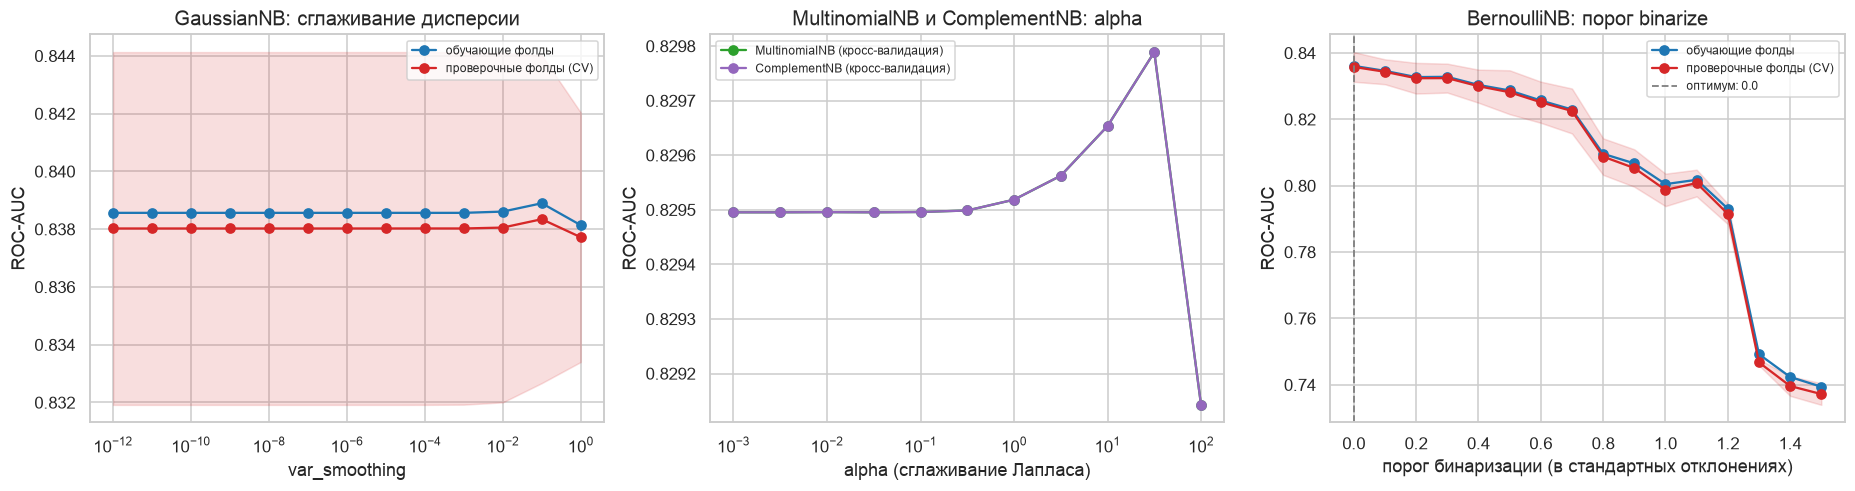

GaussianNB: лучший var_smoothing = 1e-01, ROC-AUC (CV) = 0.8383
BernoulliNB: лучший порог binarize = 0.0, ROC-AUC (CV) = 0.8358

Для сравнения: GaussianNB на сырых признаках без предобработки, ROC-AUC (тестовая выборка) = 0.7095
Лучший вариант по кросс-валидации: GaussianNB (стандартизованные)


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

vs_grid = np.logspace(-12, 0, 13)
tr, va = validation_curve(GaussianNB(), X_train, y_train, param_name="var_smoothing",
                          param_range=vs_grid, cv=cv, scoring="roc_auc")
best_vs = vs_grid[va.mean(1).argmax()]
plot_curve(axes[0], vs_grid, tr, va, "var_smoothing", "GaussianNB: сглаживание дисперсии", logx=True)

alpha_grid = np.logspace(-3, 2, 11)
for est, color, label in [(MultinomialNB(), "#2ca02c", "MultinomialNB"), (ComplementNB(), "#9467bd", "ComplementNB")]:
    _, va_a = validation_curve(est, X_train_mm, y_train, param_name="alpha", param_range=alpha_grid,
                               cv=cv, scoring="roc_auc")
    axes[1].plot(alpha_grid, va_a.mean(1), "o-", color=color, label=f"{label} (кросс-валидация)")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha (сглаживание Лапласа)")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("MultinomialNB и ComplementNB: alpha")
axes[1].legend(fontsize=8)

bin_grid = np.round(np.linspace(0.0, 1.5, 16), 2)   # в sklearn binarize >= 0
tr_b, va_b = validation_curve(BernoulliNB(), X_train, y_train, param_name="binarize",
                              param_range=bin_grid, cv=cv, scoring="roc_auc")
best_bin = bin_grid[va_b.mean(1).argmax()]
plot_curve(axes[2], bin_grid, tr_b, va_b, "порог бинаризации (в стандартных отклонениях)",
           "BernoulliNB: порог binarize", best=best_bin)
plt.tight_layout()
plt.show()

nb_grid = GridSearchCV(GaussianNB(), {"var_smoothing": vs_grid}, cv=cv, scoring="roc_auc").fit(X_train, y_train)
print(f"GaussianNB: лучший var_smoothing = {nb_grid.best_params_['var_smoothing']:.0e}, "
      f"ROC-AUC (CV) = {nb_grid.best_score_:.4f}")
print(f"BernoulliNB: лучший порог binarize = {best_bin}, ROC-AUC (CV) = {va_b.mean(1).max():.4f}")

# Исследование: GaussianNB на признаках без log-преобразования (только стандартизация)
raw_scaler = StandardScaler().fit(X_train_raw)
gnb_raw = GaussianNB().fit(raw_scaler.transform(X_train_raw), y_train)
auc_raw = roc_auc_score(y_test, gnb_raw.predict_proba(raw_scaler.transform(X_test_raw))[:, 1])
print(f"\nДля сравнения: GaussianNB на сырых признаках без предобработки, ROC-AUC (тестовая выборка) = {auc_raw:.4f}")

best_nb_name = nb_df.loc[nb_df["ROC-AUC (CV)"].idxmax(), "Модель"]
print(f"Лучший вариант по кросс-валидации: {best_nb_name}")

### Пояснение к настройке наивного байесовского классификатора

- `var_smoothing` (GaussianNB): в диапазоне от $10^{-12}$ до $10^{-2}$ качество не изменяется (ROC-AUC при кросс-валидации около 0.838); небольшой максимум достигается при $10^{-1}$ (0.8383), при значении 1 качество снижается. После стандартизации дисперсии признаков близки к единице, поэтому малое сглаживание на них практически не влияет.
- `alpha` (MultinomialNB, ComplementNB): ROC-AUC изменяется лишь в четвёртом знаке после запятой (от 0.8295 до 0.8298 при `alpha = 30`) и снижается при `alpha = 100`. Сглаживание Лапласа существенно при нулевых частотах, а в рассматриваемых данных такие ситуации не возникают.
- `binarize` (BernoulliNB): наилучший порог равен 0, то есть признак бинаризуется относительно среднего значения (ROC-AUC 0.836). С увеличением порога качество монотонно снижается: при пороге 1.5σ большинство значений обращается в ноль, и ROC-AUC падает до 0.74. В Scikit-Learn 1.9 допустимы только неотрицательные значения порога.
- Влияние предобработки: GaussianNB, обученный на исходных признаках без ограничения выбросов и логарифмирования, достигает ROC-AUC лишь 0.71 против 0.84. Предположение о нормальности плохо согласуется с распределениями, имеющими значения до 22 000; логарифмирование приближает их к нормальным.

Таким образом, гиперпараметры наивного байесовского классификатора практически не влияют на качество: настройка повышает ROC-AUC на 0.0006, тогда как предобработка данных – на 0.13.

In [9]:
nb_def = GaussianNB().fit(X_train, y_train)
results_default.append(evaluate(nb_def, X_test, "Наивный Байес"))
nb_best = nb_grid.best_estimator_
results_tuned.append(evaluate(nb_best, X_test, "Наивный Байес"))
tuned_models["Наивный Байес"] = (nb_best, X_test)
print("GaussianNB: до и после настройки")
display(pd.DataFrame([results_default[-1], results_tuned[-1]], index=["По умолчанию", "Настроенный"]).drop(columns="Модель").round(4))

GaussianNB: до и после настройки


,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7365,0.8705,0.5554,0.6781,0.8410
Настроенный,0.7380,0.8725,0.5572,0.6801,0.8417


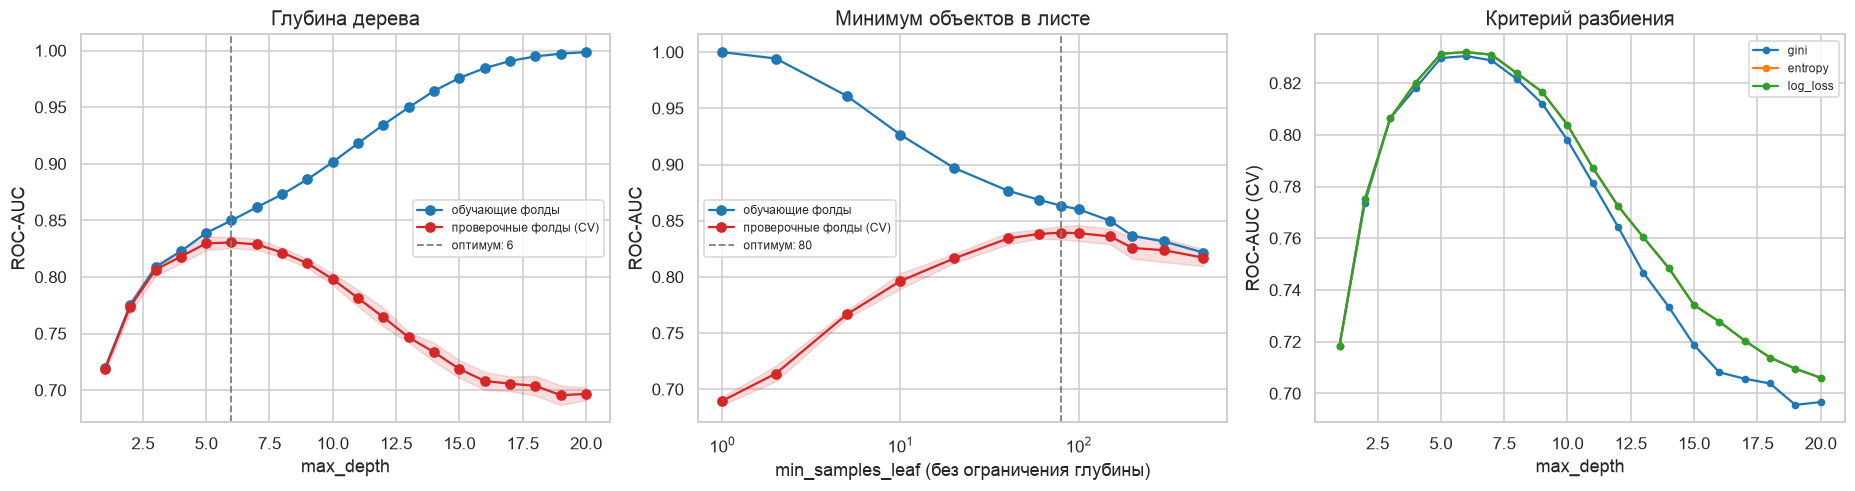

Перебрано комбинаций: 192
Лучшие параметры: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 80}
ROC-AUC (CV) = 0.8396


param_criterion,param_max_depth,param_min_samples_leaf,param_class_weight,ROC-AUC (CV),СКО
gini,10,80,None,0.839600,0.005900
gini,10,80,balanced,0.839600,0.005900
gini,12,80,balanced,0.839400,0.005800
gini,12,80,None,0.839300,0.005800
gini,None,80,balanced,0.839300,0.006100
gini,None,80,None,0.839300,0.006100
gini,8,80,balanced,0.839000,0.005400
gini,8,40,balanced,0.839000,0.004200


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

depth_grid = np.arange(1, 21)
tr, va = validation_curve(DecisionTreeClassifier(random_state=SEED), X_train, y_train,
                          param_name="max_depth", param_range=depth_grid, cv=cv, scoring="roc_auc")
plot_curve(axes[0], depth_grid, tr, va, "max_depth", "Глубина дерева", best=int(depth_grid[va.mean(1).argmax()]))

leaf_grid = np.array([1, 2, 5, 10, 20, 40, 60, 80, 100, 150, 200, 300, 500])
tr_l, va_l = validation_curve(DecisionTreeClassifier(random_state=SEED), X_train, y_train,
                              param_name="min_samples_leaf", param_range=leaf_grid, cv=cv, scoring="roc_auc")
plot_curve(axes[1], leaf_grid, tr_l, va_l, "min_samples_leaf (без ограничения глубины)",
           "Минимум объектов в листе", logx=True, best=int(leaf_grid[va_l.mean(1).argmax()]))

for crit, color in [("gini", "#1f77b4"), ("entropy", "#ff7f0e"), ("log_loss", "#2ca02c")]:
    _, va_c = validation_curve(DecisionTreeClassifier(criterion=crit, random_state=SEED), X_train, y_train,
                               param_name="max_depth", param_range=depth_grid, cv=cv, scoring="roc_auc")
    axes[2].plot(depth_grid, va_c.mean(1), "o-", ms=4, color=color, label=crit)
axes[2].set_xlabel("max_depth")
axes[2].set_ylabel("ROC-AUC (CV)")
axes[2].set_title("Критерий разбиения")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

dt_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 5, 6, 7, 8, 10, 12, None],
    "min_samples_leaf": [1, 10, 20, 40, 80, 150],
    "class_weight": [None, "balanced"],
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), dt_params, cv=cv,
                       scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Перебрано комбинаций: {len(dt_grid.cv_results_['params'])}")
print(f"Лучшие параметры: {dt_grid.best_params_}")
print(f"ROC-AUC (CV) = {dt_grid.best_score_:.4f}")
top = pd.DataFrame(dt_grid.cv_results_).sort_values("rank_test_score").head(8)
top["param_class_weight"] = top["param_class_weight"].fillna("None").astype(str)
top["param_max_depth"] = top["param_max_depth"].fillna("None").astype(str)
display(top[["param_criterion", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
             "mean_test_score", "std_test_score"]].round(4).rename(columns={
    "mean_test_score": "ROC-AUC (CV)", "std_test_score": "СКО"}).style.hide(axis="index"))

### Пояснение к настройке дерева решений

- Глубина (`max_depth`): наблюдается типичная картина переобучения. На обучающих фолдах ROC-AUC возрастает до 1.0 при глубине 20, тогда как при кросс-валидации максимум (около 0.83) достигается при глубине 5–7, после чего метрика снижается до 0.70. Глубокое дерево подстраивается под случайные особенности обучающей выборки.
- `min_samples_leaf` (без ограничения глубины): при одном объекте в листе ROC-AUC при кросс-валидации составляет 0.69 (это соответствует дереву по умолчанию), при 80 объектах достигается максимум 0.84, при 300–500 объектах модель становится слишком грубой. Ограничение размера листа эффективнее ограничения глубины: оно устраняет только ветви, построенные по малому числу объектов, и сохраняет глубину там, где данных достаточно.
- Критерий разбиения: `entropy` и `log_loss` в Scikit-Learn эквивалентны (кривые совпадают). Энтропийный критерий несколько превосходит критерий Джини при большой глубине; в оптимуме различие пренебрежимо мало.
- `GridSearchCV` (192 комбинации): наилучшие параметры – `criterion="gini"`, `max_depth=10`, `min_samples_leaf=80`, ROC-AUC при кросс-валидации 0.8396. Значение `class_weight="balanced"` даёт тот же результат, поскольку классы сбалансированы. Восемь лучших комбинаций различаются менее чем на 0.001, то есть оптимум достаточно пологий.

Дерево по умолчанию: глубина 30, листьев 2640
Настроенное дерево:  глубина 10, листьев 101


,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.6862,0.6873,0.6828,0.6851,0.6862
Настроенное,0.7703,0.7885,0.7385,0.7627,0.8472


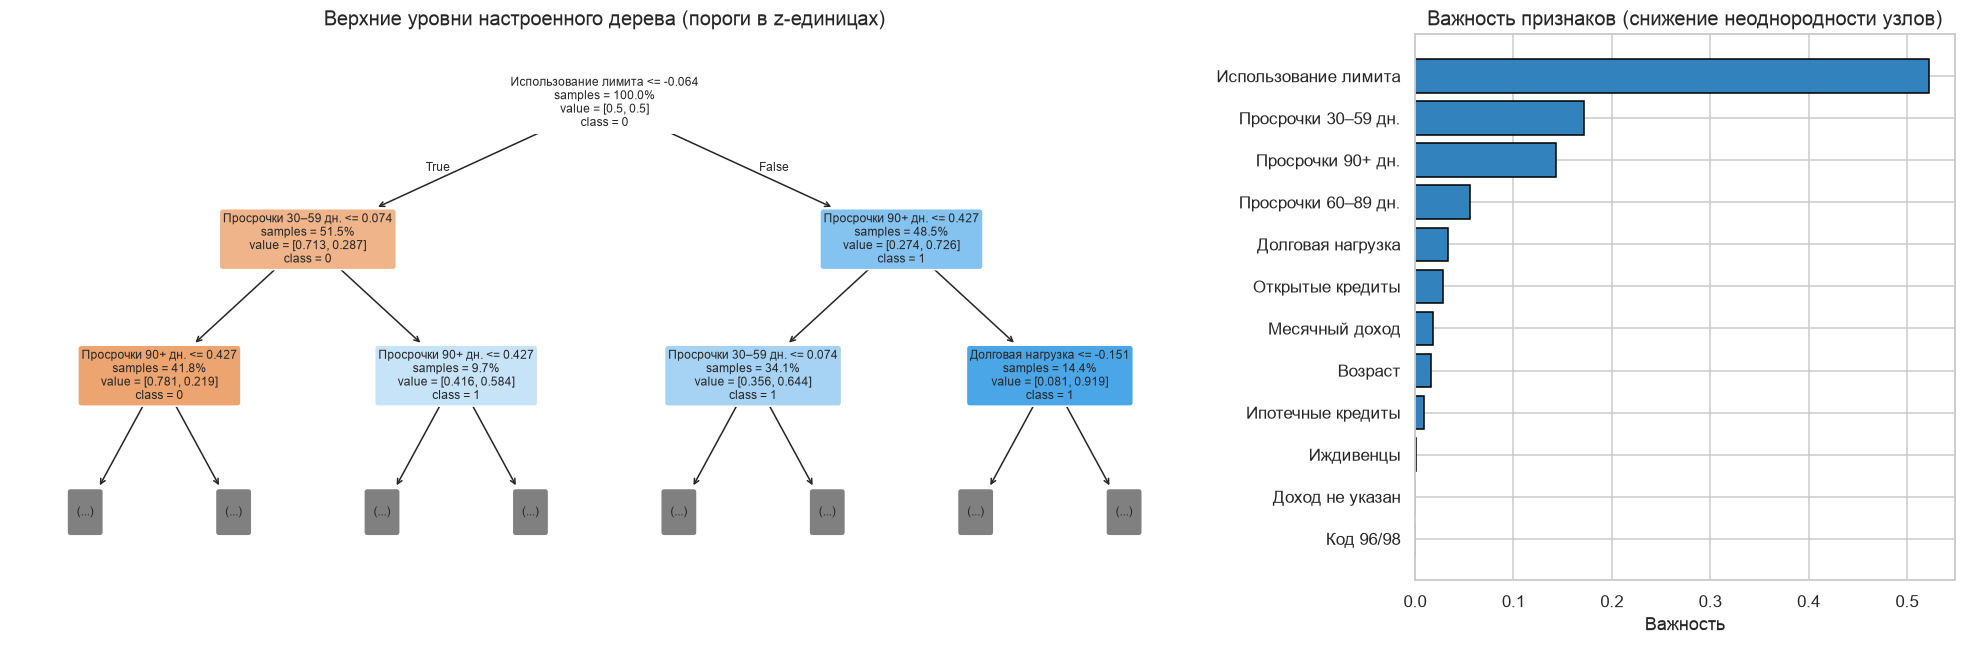

In [11]:
dt_def = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
results_default.append(evaluate(dt_def, X_test, "Дерево решений"))
dt_best = dt_grid.best_estimator_
results_tuned.append(evaluate(dt_best, X_test, "Дерево решений"))
tuned_models["Дерево решений"] = (dt_best, X_test)
print(f"Дерево по умолчанию: глубина {dt_def.get_depth()}, листьев {dt_def.get_n_leaves()}")
print(f"Настроенное дерево:  глубина {dt_best.get_depth()}, листьев {dt_best.get_n_leaves()}")
display(pd.DataFrame([results_default[-1], results_tuned[-1]], index=["По умолчанию", "Настроенное"]).drop(columns="Модель").round(4))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(dt_best, max_depth=2, feature_names=final_features, class_names=["0", "1"], filled=True,
          rounded=True, fontsize=8, ax=axes[0], impurity=False, proportion=True)
axes[0].set_title("Верхние уровни настроенного дерева (пороги в z-единицах)")
imp = pd.Series(dt_best.feature_importances_, index=final_features).sort_values()
axes[1].barh(imp.index, imp.values, color="#3182bd", edgecolor="black")
axes[1].set_title("Важность признаков (снижение неоднородности узлов)")
axes[1].set_xlabel("Важность")
plt.tight_layout()
plt.show()

### Пояснение к структуре дерева

Для дерева решений настройка гиперпараметров дала наибольший эффект среди всех методов. Дерево с параметрами по умолчанию (глубина 30, 2 640 листьев) переобучено: ROC-AUC и Accuracy на тестовой выборке равны 0.686. Настроенное дерево (глубина 10, 101 лист) достигает ROC-AUC 0.847 (+0.161) и Accuracy 0.770 (+0.084).

Верхние уровни дерева допускают содержательную интерпретацию:

- Корневое разбиение выполняется по признаку «Использование лимита» (порог близок к среднему значению). В левую ветвь попадает 51.5% заёмщиков с долей дефолтов 29%, в правую – 48.5% с долей дефолтов 73%.
- На втором уровне в обеих ветвях используются признаки «Просрочки 30–59 дн.» и «Просрочки 90+ дн.». Наибольший риск соответствует сочетанию высокого использования лимита и наличия просрочек 90+ дней: доля дефолтов в этом узле составляет 92%.

Важность признаков: «Использование лимита» – около 0.52, «Просрочки 30–59 дн.» – 0.17, «Просрочки 90+ дн.» – 0.14, «Просрочки 60–89 дн.» – 0.06; суммарная важность остальных признаков не превышает 0.15. Индикаторы «Код 96/98» и «Доход не указан» деревом практически не используются, поскольку соответствующие заёмщики уже выделяются по другим признакам.

LDA: РЕШАТЕЛИ И АВТОМАТИЧЕСКОЕ СЖАТИЕ (Ledoit–Wolf)


Модель,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV)
"solver=svd, shrinkage=None",0.761300,0.783600,0.721700,0.751400,0.847600,0.842400
"solver=lsqr, shrinkage=None",0.761300,0.783600,0.721700,0.751400,0.847600,0.842400
"solver=eigen, shrinkage=None",0.761300,0.783600,0.721700,0.751400,0.847600,0.842400
"solver=lsqr, shrinkage=auto",0.762200,0.783700,0.724100,0.752700,0.847500,0.842500
"solver=eigen, shrinkage=auto",0.762200,0.783700,0.724100,0.752700,0.847500,0.842500


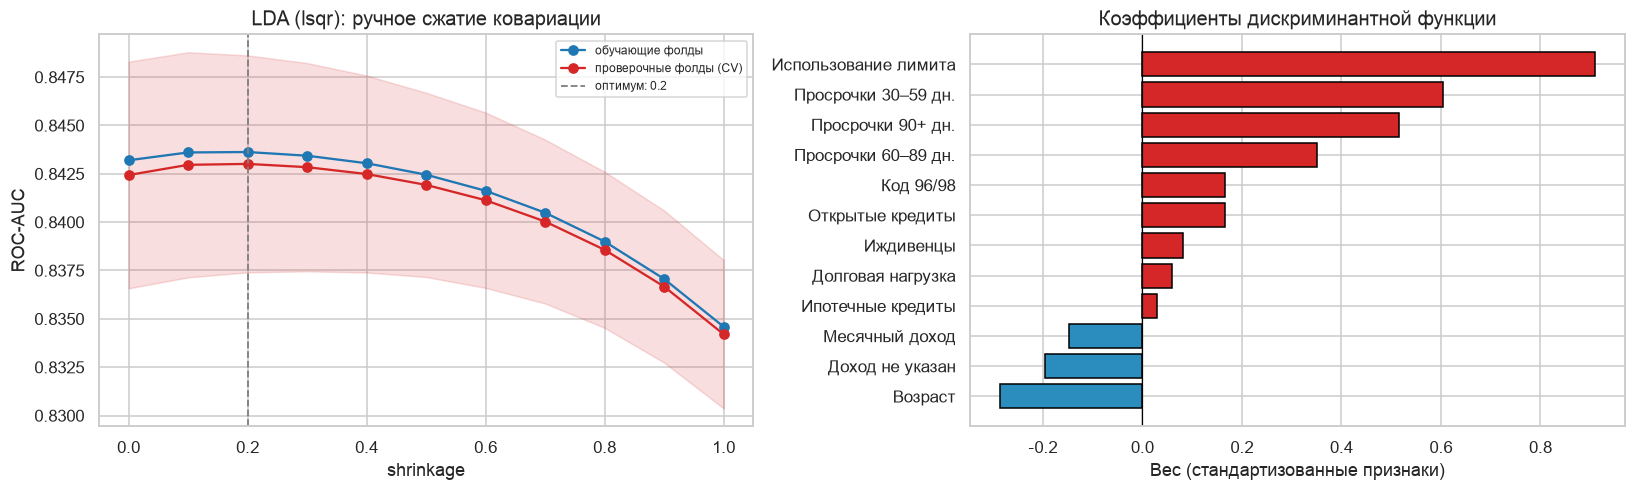

Лучшие параметры LDA: {'shrinkage': 0.2, 'solver': 'lsqr'}, ROC-AUC (CV) = 0.8430


In [12]:
rows = []
for solver, shrink in [("svd", None), ("lsqr", None), ("eigen", None), ("lsqr", "auto"), ("eigen", "auto")]:
    lda = LinearDiscriminantAnalysis(solver=solver, shrinkage=shrink)
    cv_auc = cross_val_score(lda, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    lda.fit(X_train, y_train)
    r = evaluate(lda, X_test, f"solver={solver}, shrinkage={shrink}")
    r["ROC-AUC (CV)"] = cv_auc
    rows.append(r)
print("LDA: РЕШАТЕЛИ И АВТОМАТИЧЕСКОЕ СЖАТИЕ (Ledoit–Wolf)")
display(pd.DataFrame(rows).round(4).style.hide(axis="index"))

shrink_grid = np.round(np.linspace(0, 1, 11), 1)
tr, va = validation_curve(LinearDiscriminantAnalysis(solver="lsqr"), X_train, y_train,
                          param_name="shrinkage", param_range=shrink_grid, cv=cv, scoring="roc_auc")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_curve(axes[0], shrink_grid, tr, va, "shrinkage", "LDA (lsqr): ручное сжатие ковариации",
           best=float(shrink_grid[va.mean(1).argmax()]))

lda_grid = GridSearchCV(LinearDiscriminantAnalysis(), [
    {"solver": ["svd"]},
    {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.3]},
], cv=cv, scoring="roc_auc").fit(X_train, y_train)
lda_best = lda_grid.best_estimator_
coef = pd.Series(lda_best.coef_[0], index=final_features).sort_values()
axes[1].barh(coef.index, coef.values, color=np.where(coef.values > 0, "#d62728", "#2b8cbe"), edgecolor="black")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Коэффициенты дискриминантной функции")
axes[1].set_xlabel("Вес (стандартизованные признаки)")
plt.tight_layout()
plt.show()
print(f"Лучшие параметры LDA: {lda_grid.best_params_}, ROC-AUC (CV) = {lda_grid.best_score_:.4f}")

### Пояснение к линейному дискриминантному анализу

- Методы решения `svd`, `lsqr` и `eigen` без сжатия дают идентичный результат (ROC-AUC 0.8476 на тестовой выборке, 0.8424 при кросс-валидации), поскольку представляют собой различные численные способы решения одной задачи. Сжатие по Ледуа–Вольфу (`auto`) практически не изменяет результат: 13 369 наблюдений вполне достаточно для надёжной оценки ковариационной матрицы 12 признаков.
- Ручное задание сжатия: наблюдается слабый максимум при `shrinkage = 0.2` (0.8430 при кросс-валидации). При сильном сжатии (значение, близкое к 1, при котором ковариационная матрица становится диагональной) качество снижается до 0.834. Следовательно, учёт взаимосвязей между признаками, в частности между счётчиками просрочек, полезен для модели.
- Кривые для обучающих и проверочных фолдов практически совпадают, то есть LDA не переобучается: линейная модель содержит всего 13 параметров.
- Коэффициенты дискриминантной функции согласуются с результатами разведочного анализа: риск дефолта в наибольшей степени повышают «Использование лимита» (+0.91) и просрочки (30–59 дн. – +0.60, 90+ дн. – +0.52, 60–89 дн. – +0.35), снижают – «Возраст» (−0.29), индикатор «Доход не указан» (−0.20) и «Месячный доход» (−0.15).

Итоговый ROC-AUC на тестовой выборке составляет 0.847; настройка не улучшила результат (изменение ROC-AUC −0.0004, Accuracy +0.003). После логарифмирования признаков предположение LDA о нормальном распределении классов с общей ковариационной матрицей выполняется в достаточной степени.

In [13]:
lda_def = LinearDiscriminantAnalysis().fit(X_train, y_train)
results_default.append(evaluate(lda_def, X_test, "LDA"))
results_tuned.append(evaluate(lda_best, X_test, "LDA"))
tuned_models["LDA"] = (lda_best, X_test)
display(pd.DataFrame([results_default[-1], results_tuned[-1]], index=["По умолчанию", "Настроенный"]).drop(columns="Модель").round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7613,0.7836,0.7217,0.7514,0.8476
Настроенный,0.7646,0.7893,0.7217,0.7540,0.8473


In [14]:
rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    t0 = time.time()
    svm = SVC(kernel=kernel, C=1.0, random_state=SEED, max_iter=200000).fit(X_train, y_train)
    r = evaluate(svm, X_test, kernel)
    r["Опорных векторов"] = int(svm.n_support_.sum())
    r["Время обучения, с"] = time.time() - t0
    rows.append(r)
print("SVM: СРАВНЕНИЕ ЯДЕР (C = 1, gamma = 'scale')")
display(pd.DataFrame(rows).rename(columns={"Модель": "Ядро"}).round(4).style.hide(axis="index"))

SVM: СРАВНЕНИЕ ЯДЕР (C = 1, gamma = 'scale')


Ядро,Accuracy,Precision,Recall,F1,ROC-AUC,Опорных векторов,"Время обучения, с"
linear,0.769700,0.792000,0.731300,0.760400,0.853900,7207,3.489200
poly,0.760400,0.811600,0.678000,0.738800,0.846500,7761,3.209900
rbf,0.777100,0.795300,0.746300,0.770000,0.846000,6819,4.085800
sigmoid,0.673300,0.671600,0.678000,0.674800,0.720600,4926,3.460200


### Пояснение к сравнению ядер SVM

- Линейное ядро при $C = 1$ обеспечивает наибольший ROC-AUC (0.854). Это указывает на близость границы между классами к линейной, что согласуется с результатом LDA.
- RBF-ядро даёт наибольшие значения Accuracy (0.777) и F1 (0.770), однако ROC-AUC равен 0.846: при `gamma='scale'` ядро оказывается слишком узким (см. исследование ниже).
- Полиномиальное ядро (степень 3) характеризуется высоким Precision (0.81) при низком Recall (0.68).
- Сигмоидальное ядро существенно уступает остальным (ROC-AUC 0.72): оно не является положительно определённым при произвольных параметрах и плохо подходит для рассматриваемых данных.

Число опорных векторов составляет от 5 до 8 тыс. при 13 тыс. обучающих объектов: классы сильно перекрываются, и значительная часть объектов попадает в полосу зазора. Время обучения составляет 3–4 с; SVM – наиболее ресурсоёмкий из пяти методов (сложность обучения растёт примерно квадратично с объёмом выборки).

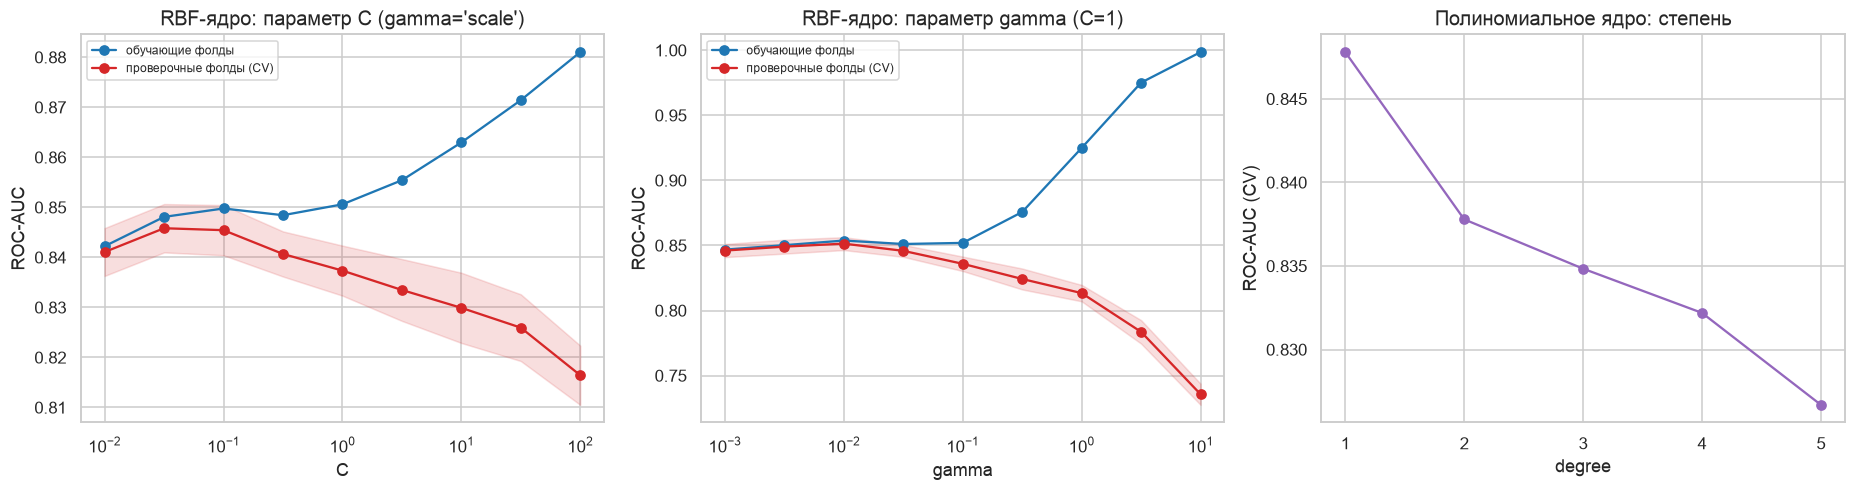

Лучшие параметры SVM: {'C': 0.3, 'gamma': 0.02}, ROC-AUC (CV) = 0.8509
ROC-AUC (CV) по сетке C × gamma:


param_gamma,0.02,0.05,0.1,scale
param_C,,,,
0.3,0.8509,0.8459,0.8394,0.8408
1.0,0.8493,0.8417,0.8359,0.8373
3.0,0.8461,0.8386,0.8316,0.8336
10.0,0.8426,0.8349,0.8281,0.8299


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
C_grid = np.logspace(-2, 2, 9)
tr, va = validation_curve(SVC(kernel="rbf"), X_train, y_train, param_name="C", param_range=C_grid,
                          cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[0], C_grid, tr, va, "C", "RBF-ядро: параметр C (gamma='scale')", logx=True)

g_grid = np.logspace(-3, 1, 9)
tr_g, va_g = validation_curve(SVC(kernel="rbf", C=1.0), X_train, y_train, param_name="gamma",
                              param_range=g_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[1], g_grid, tr_g, va_g, "gamma", "RBF-ядро: параметр gamma (C=1)", logx=True)

deg_grid = [1, 2, 3, 4, 5]
_, va_d = validation_curve(SVC(kernel="poly", C=1.0), X_train, y_train, param_name="degree",
                           param_range=deg_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
axes[2].plot(deg_grid, va_d.mean(1), "o-", color="#9467bd")
axes[2].set_xticks(deg_grid)
axes[2].set_xlabel("degree")
axes[2].set_ylabel("ROC-AUC (CV)")
axes[2].set_title("Полиномиальное ядро: степень")
plt.tight_layout()
plt.show()

svm_grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.3, 1, 3, 10], "gamma": ["scale", 0.02, 0.05, 0.1]},
                        cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Лучшие параметры SVM: {svm_grid.best_params_}, ROC-AUC (CV) = {svm_grid.best_score_:.4f}")
pivot = pd.DataFrame(svm_grid.cv_results_).pivot_table(index="param_C", columns="param_gamma",
                                                       values="mean_test_score")
print("ROC-AUC (CV) по сетке C × gamma:")
display(pivot.round(4))

### Пояснение к настройке SVM

- Параметр $C$ (RBF-ядро, `gamma='scale'`): на обучающих фолдах ROC-AUC возрастает с ростом $C$ (с 0.84 до 0.88), а при кросс-валидации снижается при $C$ больше 0.03–0.1 (с 0.846 до 0.816 при $C = 100$). Большое значение $C$ требует корректно классифицировать почти все обучающие объекты, граница усложняется, и модель переобучается.
- Параметр $\gamma$ ($C = 1$): при $\gamma \le 0.01$ кривые для обучающих и проверочных фолдов совпадают (около 0.85). При $\gamma \ge 0.1$ ROC-AUC на обучающих фолдах приближается к 1.0, а при кросс-валидации снижается до 0.73 при $\gamma = 10$: слишком узкое ядро описывает окрестность каждого объекта отдельно. Значение `'scale'` равно $1/(d \cdot \operatorname{Var}X) \approx 0.083$, то есть превышает оптимальное.
- Степень полиномиального ядра: наилучший результат даёт степень 1 (0.848); с ростом степени качество монотонно снижается.
- `GridSearchCV`: наилучшие параметры – $C = 0.3$, $\gamma = 0.02$, ROC-AUC при кросс-валидации 0.8509. Как видно из таблицы, наилучшие значения сосредоточены при малых $C$ и $\gamma$, что соответствует гладкой, близкой к линейной границе.

На тестовой выборке настройка повысила ROC-AUC до 0.856 (+0.010), а Recall – до 0.762 (+0.016).

In [16]:
svm_def = SVC().fit(X_train, y_train)
results_default.append(evaluate(svm_def, X_test, "SVM"))
svm_best = svm_grid.best_estimator_
results_tuned.append(evaluate(svm_best, X_test, "SVM"))
tuned_models["SVM"] = (svm_best, X_test)
display(pd.DataFrame([results_default[-1], results_tuned[-1]], index=["По умолчанию", "Настроенный"]).drop(columns="Модель").round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7771,0.7953,0.7463,0.7700,0.8460
Настроенный,0.7777,0.7864,0.7624,0.7742,0.8557


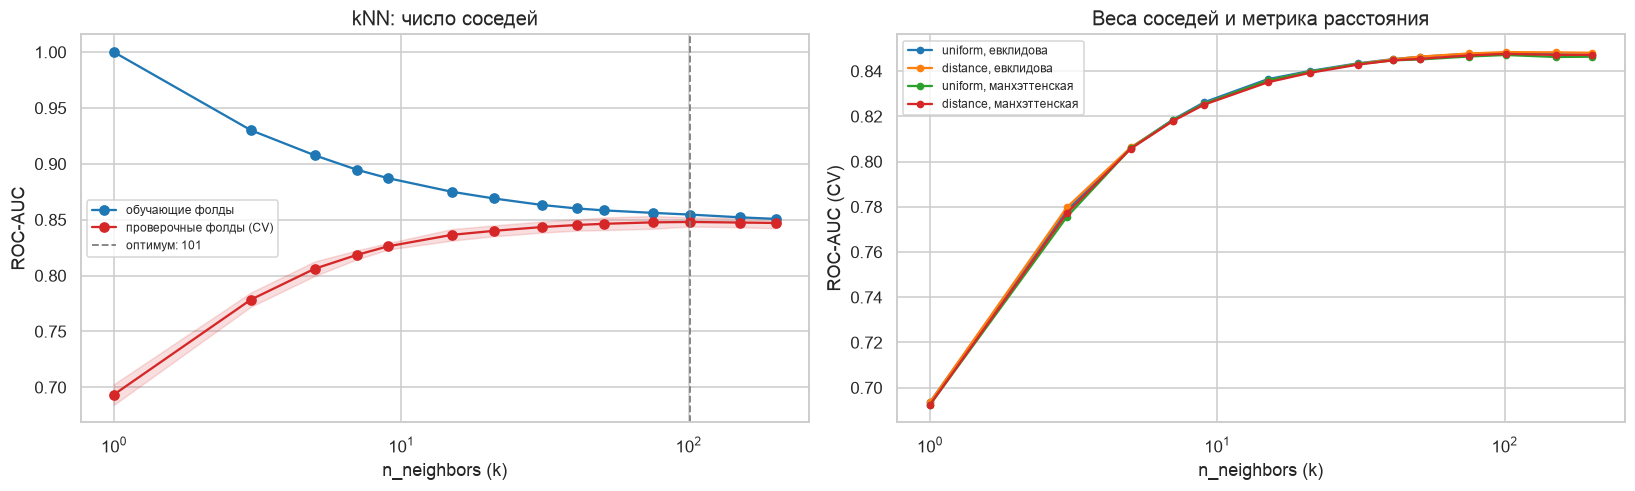

Лучшие параметры kNN: {'n_neighbors': 101, 'p': 2, 'weights': 'distance'}, ROC-AUC (CV) = 0.8484
kNN с теми же параметрами без стандартизации: ROC-AUC (тестовая выборка) = 0.7632


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
k_grid = np.array([1, 3, 5, 7, 9, 15, 21, 31, 41, 51, 75, 101, 151, 201])
tr, va = validation_curve(KNeighborsClassifier(), X_train, y_train, param_name="n_neighbors",
                          param_range=k_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[0], k_grid, tr, va, "n_neighbors (k)", "kNN: число соседей", logx=True,
           best=int(k_grid[va.mean(1).argmax()]))

for weights, p, color in [("uniform", 2, "#1f77b4"), ("distance", 2, "#ff7f0e"),
                          ("uniform", 1, "#2ca02c"), ("distance", 1, "#d62728")]:
    _, va_w = validation_curve(KNeighborsClassifier(weights=weights, p=p), X_train, y_train,
                               param_name="n_neighbors", param_range=k_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    axes[1].plot(k_grid, va_w.mean(1), "o-", ms=4, color=color,
                 label=f"{weights}, {'евклидова' if p == 2 else 'манхэттенская'}")
axes[1].set_xscale("log")
axes[1].set_xlabel("n_neighbors (k)")
axes[1].set_ylabel("ROC-AUC (CV)")
axes[1].set_title("Веса соседей и метрика расстояния")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

knn_grid = GridSearchCV(KNeighborsClassifier(), {
    "n_neighbors": [31, 51, 75, 101, 151],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Лучшие параметры kNN: {knn_grid.best_params_}, ROC-AUC (CV) = {knn_grid.best_score_:.4f}")

# Влияние масштабирования: kNN без стандартизации
knn_noscale = KNeighborsClassifier(**knn_grid.best_params_).fit(X_train_p, y_train)
print(f"kNN с теми же параметрами без стандартизации: ROC-AUC (тестовая выборка) = "
      f"{roc_auc_score(y_test, knn_noscale.predict_proba(X_test_p)[:, 1]):.4f}")

### Пояснение к настройке метода k ближайших соседей

- Число соседей $k$: при $k = 1$ модель безошибочно воспроизводит обучающую выборку (ROC-AUC 1.0), тогда как при кросс-валидации ROC-AUC составляет лишь 0.69. С ростом $k$ кривые сближаются; при кросс-валидации ROC-AUC выходит на плато 0.848 при $k$ от 75 до 150. Поскольку классы сильно перекрываются, для оценки вероятности дефолта требуется усреднение по большой окрестности; значение $k = 5$, используемое по умолчанию, явно недостаточно.
- Весовая схема и метрика: взвешивание по расстоянию (`distance`) и равные веса (`uniform`), евклидова и манхэттенская метрики дают практически совпадающие кривые (различие менее 0.002).
- `GridSearchCV`: наилучшие параметры – `n_neighbors=101`, `weights='distance'`, `p=2` (евклидова метрика), ROC-AUC при кросс-валидации 0.8484.
- Влияние масштабирования: модель с теми же параметрами без стандартизации достигает ROC-AUC лишь 0.763 против 0.855. В этом случае расстояние определяется преимущественно логарифмом дохода (порядка 8–10) и возрастом (десятки лет), а признаки-доли практически не учитываются.

На тестовой выборке настройка повысила ROC-AUC с 0.810 до 0.855 (+0.044).

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7505,0.7595,0.7331,0.7460,0.8103
Настроенный,0.7637,0.7962,0.7086,0.7498,0.8545


ВЛИЯНИЕ НАСТРОЙКИ: прирост метрик (настроенная − по умолчанию)


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Наивный Байес,0.0015,0.0020,0.0018,0.0019,0.0006
Дерево решений,0.0841,0.1011,0.0557,0.0776,0.1610
LDA,0.0033,0.0056,0.0000,0.0026,-0.0004
SVM,0.0006,-0.0089,0.0162,0.0042,0.0096
kNN,0.0132,0.0368,-0.0245,0.0038,0.0442


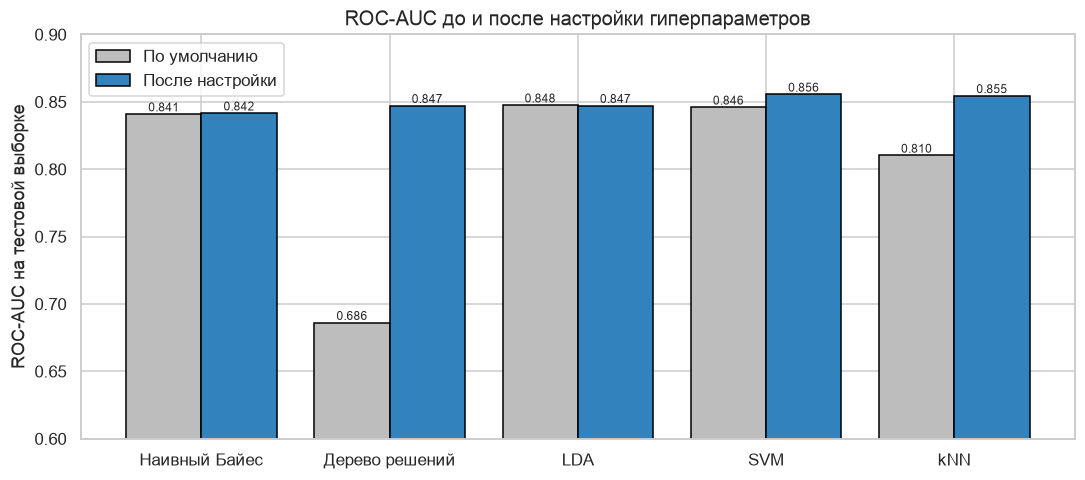

In [18]:
knn_def = KNeighborsClassifier().fit(X_train, y_train)
results_default.append(evaluate(knn_def, X_test, "kNN"))
knn_best = knn_grid.best_estimator_
results_tuned.append(evaluate(knn_best, X_test, "kNN"))
tuned_models["kNN"] = (knn_best, X_test)
display(pd.DataFrame([results_default[-1], results_tuned[-1]], index=["По умолчанию", "Настроенный"]).drop(columns="Модель").round(4))

df_def = pd.DataFrame(results_default).set_index("Модель")
df_tun = pd.DataFrame(results_tuned).set_index("Модель")
print("ВЛИЯНИЕ НАСТРОЙКИ: прирост метрик (настроенная − по умолчанию)")
display((df_tun - df_def).round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(df_def))
b1 = ax.bar(x - 0.2, df_def["ROC-AUC"], 0.4, label="По умолчанию", color="#bdbdbd", edgecolor="black")
b2 = ax.bar(x + 0.2, df_tun["ROC-AUC"], 0.4, label="После настройки", color="#3182bd", edgecolor="black")
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(df_def.index)
ax.set_ylim(0.6, 0.9)
ax.set_ylabel("ROC-AUC на тестовой выборке")
ax.set_title("ROC-AUC до и после настройки гиперпараметров")
ax.legend()
plt.tight_layout()
plt.show()

### Пояснение к влиянию настройки гиперпараметров

| Метод | Основные параметры | ΔROC-AUC (тестовая выборка) | Объяснение |
|---|---|---|---|
| Дерево решений | `max_depth=10`, `min_samples_leaf=80` | +0.161 | дерево по умолчанию переобучено (2 640 листьев) |
| kNN | `n_neighbors=101`, `weights='distance'` | +0.044 | значение $k = 5$ недостаточно при перекрывающихся классах |
| SVM | $C = 0.3$, $\gamma = 0.02$ | +0.010 | более гладкая разделяющая граница |
| Наивный байесовский классификатор | `var_smoothing=0.1` | +0.001 | у метода практически нет значимых гиперпараметров |
| LDA | `solver='lsqr'`, `shrinkage=0.2` | −0.0004 | объём данных достаточен для надёжной оценки ковариации |

Наибольший выигрыш от настройки получают гибкие непараметрические методы (дерево решений, kNN): при параметрах по умолчанию их сложность избыточна, и регуляризация оказывается основным средством повышения качества. Качество простых параметрических моделей (наивный байесовский классификатор, LDA) определяется прежде всего предобработкой данных.

## 6. Нейронная сеть на TensorFlow

Используется полносвязная нейронная сеть (многослойный перцептрон), построенная средствами Keras API:

- Входной слой – 12 стандартизованных признаков (те же, что и для моделей Scikit-Learn).
- Скрытые слои – слои `Dense` с функцией активации (по умолчанию ReLU, $f(z) = \max(0, z)$); при необходимости добавляются слои `Dropout`.
- Выходной слой – один нейрон с сигмоидной функцией активации $\sigma(z) = \frac{1}{1 + e^{-z}}$, выдающий вероятность дефолта.
- Функция потерь – бинарная кросс-энтропия $L = -\frac1n\sum_i \left[y_i \ln p_i + (1-y_i)\ln(1-p_i)\right]$.
- Оптимизатор – Adam (адаптивный градиентный спуск с оценками моментов), скорость обучения по умолчанию $10^{-3}$.
- Метрики – accuracy и ROC-AUC, вычисляемые после каждой эпохи.

Из обучающей выборки выделено 15% объектов для валидации: по валидационной выборке сравниваются варианты сети и определяется момент остановки обучения. Тестовая выборка используется только для оценки итоговой модели.

Каждый запуск записывает логи в каталог `logs/fit/<эксперимент>/<вариант>` с помощью `keras.callbacks.TensorBoard`: скалярные метрики (функция потерь, accuracy, ROC-AUC) для обучающей и валидационной выборок, а также гистограммы весов на каждой эпохе.

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print(f"TensorFlow {tf.__version__}")

LOG_ROOT = "logs/fit"
shutil.rmtree(LOG_ROOT, ignore_errors=True)

# отдельная валидационная выборка из train (15%) – общая для всех экспериментов
X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train.values.astype("float32"), y_train.values.astype("float32"),
    test_size=0.15, random_state=SEED, stratify=y_train,
)
X_te_nn = X_test.values.astype("float32")
print(f"NN: train {len(X_tr_nn)}, validation {len(X_val_nn)}, test {len(X_te_nn)}")


def build_model(hidden=(64, 32), activation="relu", dropout=0.0, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(X_tr_nn.shape[1],))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model


nn_runs = []      # сводка всех запусков
nn_hist = {}      # истории обучения


def run_experiment(group, name, hidden=(64, 32), activation="relu", dropout=0.0, lr=1e-3,
                   epochs=50, batch_size=64, early_stop=False, verbose=0):
    keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, dropout, lr)
    callbacks = [keras.callbacks.TensorBoard(log_dir=f"{LOG_ROOT}/{group}/{name}", histogram_freq=1)]
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                       restore_best_weights=True))
    t0 = time.time()
    h = model.fit(X_tr_nn, y_tr_nn, validation_data=(X_val_nn, y_val_nn), epochs=epochs,
                  batch_size=batch_size, callbacks=callbacks, verbose=verbose)
    elapsed = time.time() - t0
    hist = pd.DataFrame(h.history)
    hist.index += 1
    nn_hist[(group, name)] = hist
    val_loss, val_acc, val_auc = model.evaluate(X_val_nn, y_val_nn, verbose=0)
    nn_runs.append({
        "config": dict(hidden=hidden, activation=activation, dropout=dropout, lr=lr, batch_size=batch_size),
        "Эксперимент": group, "Вариант": name, "Эпох": len(hist), "Параметров": model.count_params(),
        "Лучшая эпоха (val_loss)": int(hist["val_loss"].idxmin()),
        "Мин. val_loss": hist["val_loss"].min(),
        "val_loss (финал)": val_loss, "val_accuracy": val_acc, "val_AUC": val_auc,
        "Время, с": elapsed,
    })
    return model, hist


def show_group(group, metric="val_loss", title=None):
    runs = [(n, h) for (g, n), h in nn_hist.items() if g == group]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    for (n, h), c in zip(runs, sns.color_palette("tab10", len(runs))):
        axes[0].plot(h.index, h["loss"], color=c, label=n)
        axes[1].plot(h.index, h["val_loss"], color=c, label=n)
        axes[2].plot(h.index, h["val_auc"], color=c, label=n)
    for ax, t in zip(axes, ["Потери (обучающая выборка)", "Потери (валидационная выборка)", "ROC-AUC (валидационная выборка)"]):
        ax.set_title(t)
        ax.set_xlabel("Эпоха")
    axes[0].legend(fontsize=8)
    plt.suptitle(title or group, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame([r for r in nn_runs if r["Эксперимент"] == group]).drop(columns=["Эксперимент", "config"])
            .round(4).style.hide(axis="index"))

TensorFlow 2.21.0
NN: train 11363, validation 2006, test 3343


### Пояснение к организации экспериментов

- Обучающая выборка (13 369 объектов) стратифицированно разделена на 11 363 объекта для обучения и 2 006 – для валидации. Валидационная выборка одинакова для всех запусков, что обеспечивает корректное сравнение вариантов.
- Перед каждым запуском вызывается `keras.utils.set_random_seed(42)`, а также включается `enable_op_determinism()`; благодаря этому инициализация весов и порядок батчей совпадают, а результаты полностью воспроизводимы.
- Функция `run_experiment` обучает модель с заданными гиперпараметрами, записывает логи TensorBoard и сохраняет сводку: минимальное значение функции потерь на валидации (`val_loss`) и номер эпохи, на которой оно достигнуто, итоговые `val_loss`, `val_accuracy`, `val_AUC` и время обучения.
- Основной критерий сравнения – минимальное значение `val_loss`, то есть качество сети при своевременной остановке обучения. Итоговое значение `val_loss` после фиксированного числа эпох характеризует степень переобучения.

In [20]:
base_model = build_model()
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

### Базовая архитектура

| Слой | Размер выхода | Число параметров | Функция активации |
|---|---|---|---|
| Входной | 12 | – | – |
| Dense | 64 | 12·64 + 64 = 832 | ReLU |
| Dense | 32 | 64·32 + 32 = 2 080 | ReLU |
| Dense (выходной) | 1 | 32 + 1 = 33 | sigmoid |

Общее число обучаемых параметров – 2 945; оптимизатор Adam (скорость обучения $10^{-3}$), функция потерь – бинарная кросс-энтропия, размер батча – 64.

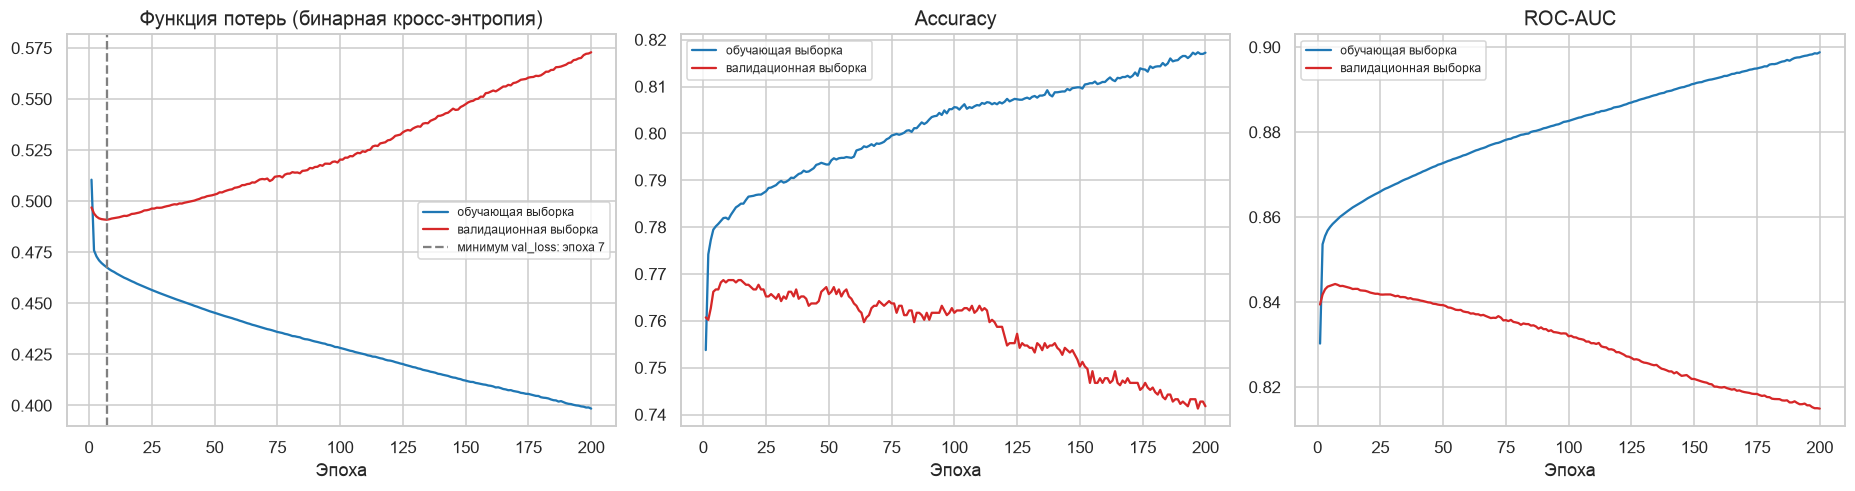

Метрики после N эпох (базовая сеть 64-32, batch 64):


,loss,val_loss,accuracy,val_accuracy,auc,val_auc
Эпох,,,,,,
5,0.4697,0.4912,0.7802,0.7667,0.8577,0.8438
10,0.4654,0.4917,0.7817,0.7687,0.8605,0.8438
20,0.4591,0.4944,0.7867,0.7667,0.8644,0.8425
30,0.4541,0.4972,0.7895,0.7657,0.8675,0.8416
50,0.4454,0.5032,0.7934,0.7657,0.8727,0.8393
75,0.4360,0.5122,0.7995,0.7637,0.8782,0.8358
100,0.4282,0.5204,0.8056,0.7617,0.8826,0.8319
150,0.4122,0.5475,0.8098,0.7502,0.8914,0.8219
200,0.3985,0.5729,0.8172,0.7418,0.8988,0.8149


In [21]:
model_long, hist_long = run_experiment("1_epochs", "200 эпох", epochs=200)
best_ep = int(hist_long["val_loss"].idxmin())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(hist_long.index, hist_long["loss"], label="обучающая выборка", color="#1f77b4")
axes[0].plot(hist_long.index, hist_long["val_loss"], label="валидационная выборка", color="#d62728")
axes[0].axvline(best_ep, color="gray", linestyle="--", label=f"минимум val_loss: эпоха {best_ep}")
axes[0].set_title("Функция потерь (бинарная кросс-энтропия)")
axes[1].plot(hist_long.index, hist_long["accuracy"], label="обучающая выборка", color="#1f77b4")
axes[1].plot(hist_long.index, hist_long["val_accuracy"], label="валидационная выборка", color="#d62728")
axes[1].set_title("Accuracy")
axes[2].plot(hist_long.index, hist_long["auc"], label="обучающая выборка", color="#1f77b4")
axes[2].plot(hist_long.index, hist_long["val_auc"], label="валидационная выборка", color="#d62728")
axes[2].set_title("ROC-AUC")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

checkpoints = [5, 10, 20, 30, 50, 75, 100, 150, 200]
print("Метрики после N эпох (базовая сеть 64-32, batch 64):")
display(hist_long.loc[checkpoints, ["loss", "val_loss", "accuracy", "val_accuracy", "auc", "val_auc"]]
        .rename_axis("Эпох").round(4))

### Пояснение к исследованию числа эпох

Базовая сеть обучалась в течение 200 эпох без ранней остановки. Значения метрик после $N$ эпох, приведённые в таблице, совпадают с результатом обучения ровно на $N$ эпох, поскольку скорость обучения постоянна, а начальное состояние генератора случайных чисел одинаково.

- Функция потерь на обучающей выборке монотонно убывает: с 0.470 (5 эпох) до 0.399 (200 эпох); ROC-AUC на обучающей выборке возрастает с 0.858 до 0.899.
- Функция потерь на валидационной выборке достигает минимума уже на 7-й эпохе (около 0.491), после чего возрастает: 0.503 к 50-й эпохе и 0.573 к 200-й. ROC-AUC на валидации снижается с 0.844 до 0.815, accuracy – с 0.769 до 0.742.
- Расхождение кривых для обучающей и валидационной выборок – характерный признак переобучения: 2 945 параметров достаточно, чтобы запомнить случайные особенности 11 тыс. обучающих объектов, тогда как устойчивая закономерность усваивается за 5–10 эпох.

Следовательно, число эпох нельзя выбирать с запасом без применения регуляризации. Необходимы ранняя остановка (`EarlyStopping`) и (или) прореживание (dropout); оба подхода исследуются далее.

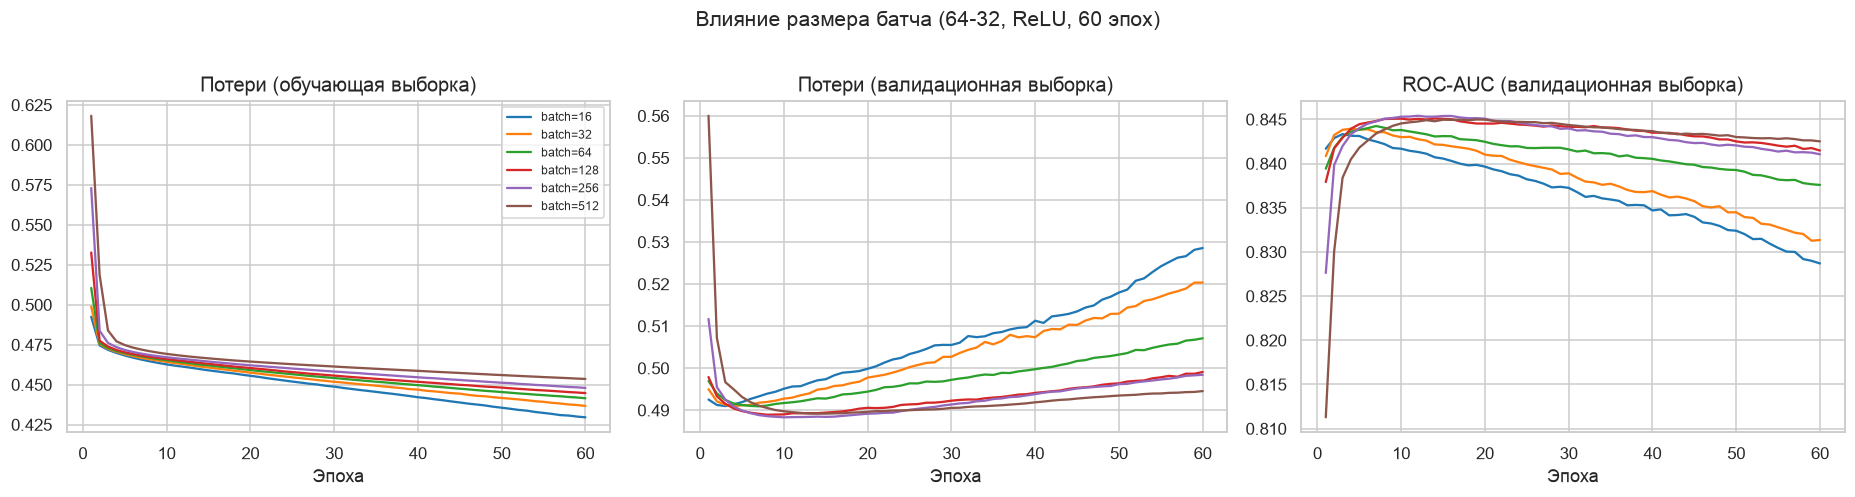

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,val_loss (финал),val_accuracy,val_AUC,"Время, с"
batch=16,60,2945,3,0.491000,0.528600,0.759700,0.828700,32.591500
batch=32,60,2945,4,0.491000,0.520400,0.760700,0.831300,19.067100
batch=64,60,2945,7,0.490900,0.507100,0.763700,0.837600,11.504200
batch=128,60,2945,8,0.488900,0.499100,0.764700,0.841500,8.284300
batch=256,60,2945,10,0.488300,0.498400,0.766200,0.841000,6.330700
batch=512,60,2945,14,0.489200,0.494500,0.770700,0.842500,5.451200


In [22]:
for bs in [16, 32, 64, 128, 256, 512]:
    run_experiment("2_batch", f"batch={bs}", batch_size=bs, epochs=60)
show_group("2_batch", title="Влияние размера батча (64-32, ReLU, 60 эпох)")

### Пояснение к исследованию размера батча

Архитектура 64-32, 60 эпох; варьируется только размер батча.

- Малый батч (16, 32) соответствует большому числу шагов градиентного спуска за эпоху (711 шагов при размере 16). Минимум `val_loss` достигается уже на 3–4-й эпохе, после чего сеть быстро переобучается: итоговое значение `val_loss` составляет 0.529 и 0.520, ROC-AUC на валидации – 0.829 и 0.831. Время обучения максимально – 33 с.
- Большой батч (256, 512) уменьшает число шагов в 16–32 раза; градиент усредняется по большему числу объектов, поэтому обучение протекает медленнее и устойчивее. Минимум `val_loss` достигается на 10–14-й эпохе, итоговые значения `val_loss` – 0.498 и 0.495, ROC-AUC на валидации – 0.841–0.843. Время обучения – 5–6 с.
- Минимальное значение `val_loss` практически не зависит от размера батча (0.488–0.491): при своевременной остановке результат одинаков. Размер батча влияет главным образом на скорость обучения и скорость наступления переобучения.

Для последующих экспериментов выбран размер батча 128 как компромисс между устойчивостью обучения и числом шагов оптимизации.

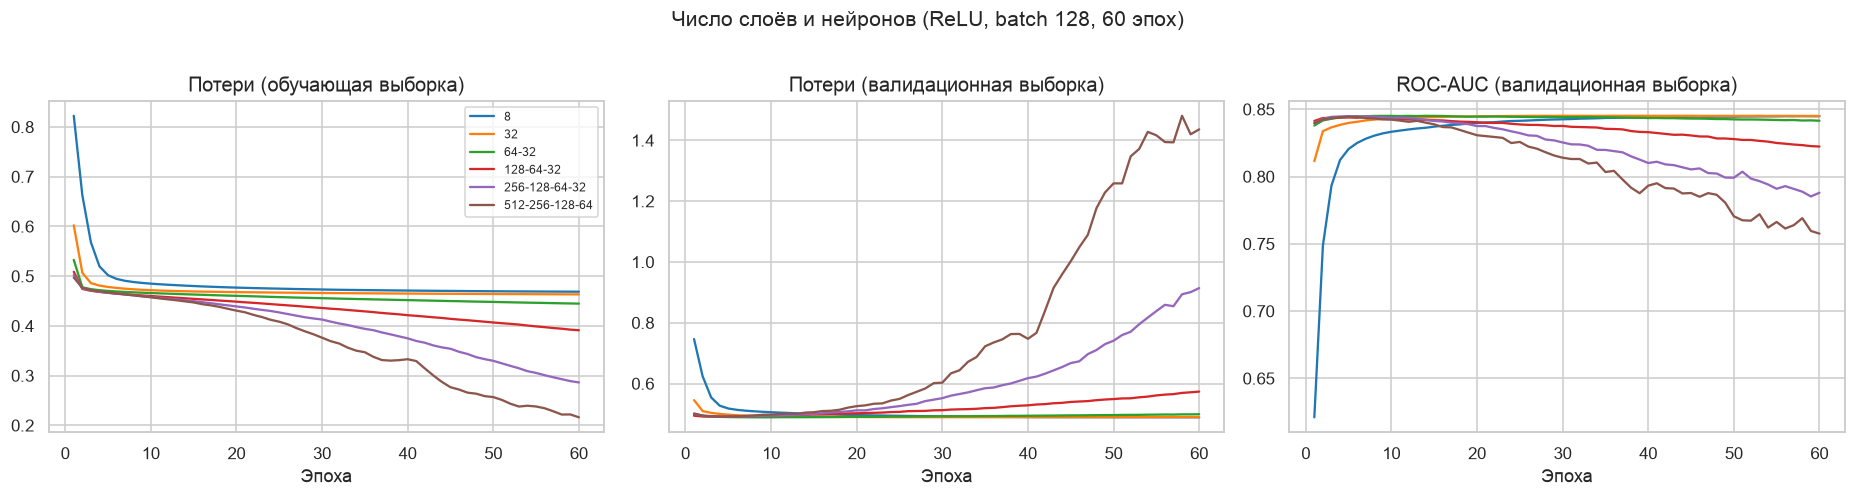

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,val_loss (финал),val_accuracy,val_AUC,"Время, с"
8,60,113,60,0.489000,0.489000,0.768700,0.844900,7.311500
32,60,449,36,0.489300,0.489800,0.769200,0.845000,7.380600
64-32,60,2945,8,0.488900,0.499100,0.764700,0.841500,8.546000
128-64-32,60,12033,4,0.491300,0.573500,0.750200,0.822300,9.173200
256-128-64-32,60,46593,7,0.491800,0.914000,0.729800,0.788000,11.134300
512-256-128-64,60,179201,4,0.491200,1.435900,0.713400,0.757600,14.953400


In [23]:
architectures = {
    "8": (8,),
    "32": (32,),
    "64-32": (64, 32),
    "128-64-32": (128, 64, 32),
    "256-128-64-32": (256, 128, 64, 32),
    "512-256-128-64": (512, 256, 128, 64),
}
for name, hidden in architectures.items():
    run_experiment("3_layers", name, hidden=hidden, epochs=60, batch_size=128)
show_group("3_layers", title="Число слоёв и нейронов (ReLU, batch 128, 60 эпох)")

### Пояснение к исследованию числа слоёв и нейронов

Функция активации ReLU, размер батча 128, 60 эпох, без регуляризации.

| Архитектура | Число параметров | Минимальный `val_loss` | Итоговый `val_loss` | Итоговый ROC-AUC (валидация) |
|---|---|---|---|---|
| 8 | 113 | 0.489 | 0.489 | 0.845 |
| 32 | 449 | 0.489 | 0.490 | 0.845 |
| 64-32 | 2 945 | 0.489 | 0.499 | 0.842 |
| 128-64-32 | 12 033 | 0.491 | 0.574 | 0.822 |
| 256-128-64-32 | 46 593 | 0.492 | 0.914 | 0.788 |
| 512-256-128-64 | 179 201 | 0.491 | 1.436 | 0.758 |

- Наилучший достижимый результат (минимальный `val_loss` около 0.489) одинаков для всех архитектур: зависимость в данных проста, и её воспроизводит даже сеть из 8 нейронов. Это согласуется с тем, что модели с близкой к линейной границей (LDA, SVM) входят в число лучших.
- Степень переобучения возрастает с размером сети. Малые сети за 60 эпох не переобучаются (у сети из 8 нейронов минимум достигается на 60-й эпохе), тогда как у сети со 179 тыс. параметров `val_loss` к 60-й эпохе возрастает втрое, а ROC-AUC на валидации снижается до 0.758.
- Крупные сети достигают минимума `val_loss` за 4–7 эпох; именно в этот момент их обучение следует останавливать.

Таким образом, для табличных данных такого объёма увеличение глубины сети не приводит к повышению качества; крупные сети применимы только в сочетании с регуляризацией.

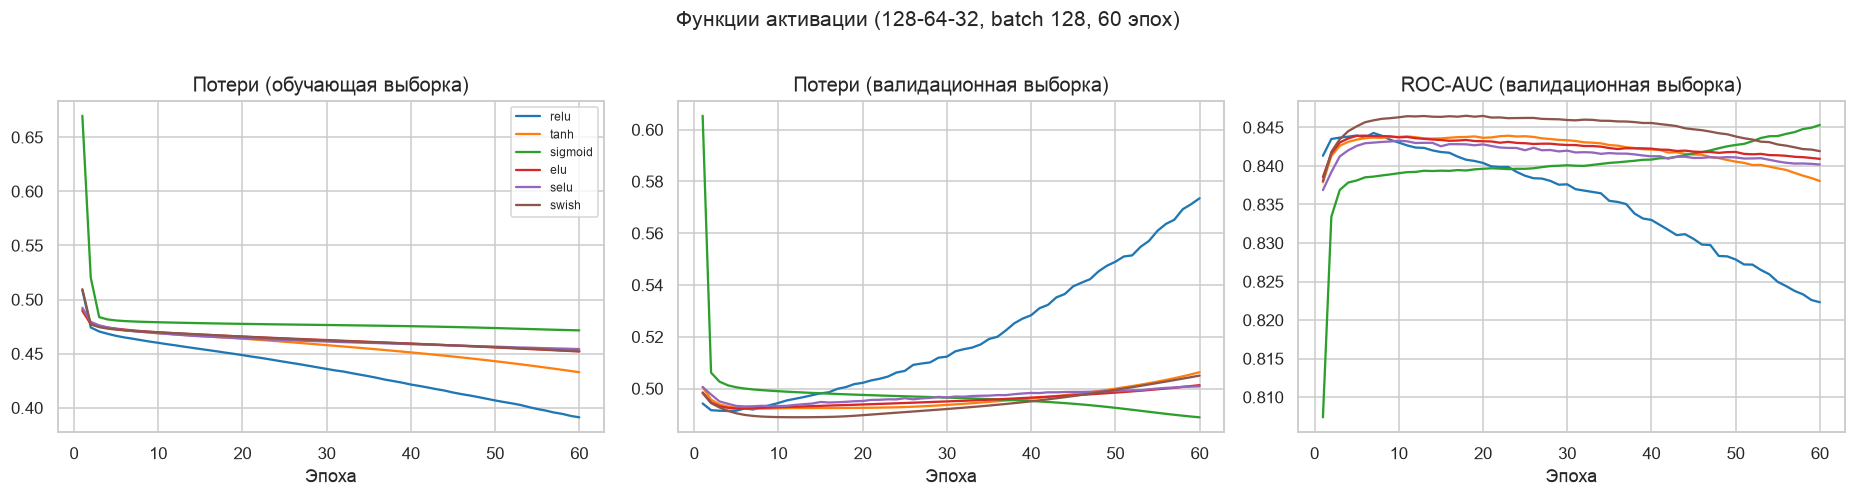

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,val_loss (финал),val_accuracy,val_AUC,"Время, с"
relu,60,12033,4,0.491300,0.573500,0.750200,0.822300,9.070800
tanh,60,12033,8,0.492300,0.506300,0.764700,0.838000,9.197900
sigmoid,60,12033,60,0.488900,0.488900,0.768200,0.845300,9.274600
elu,60,12033,6,0.492300,0.501300,0.770700,0.840900,9.501700
selu,60,12033,6,0.493100,0.500800,0.768700,0.840200,9.281500
swish,60,12033,12,0.488900,0.505000,0.766700,0.841900,9.642800


In [24]:
for act in ["relu", "tanh", "sigmoid", "elu", "selu", "swish"]:
    run_experiment("4_activation", act, activation=act, hidden=(128, 64, 32), epochs=60, batch_size=128)
show_group("4_activation", title="Функции активации (128-64-32, batch 128, 60 эпох)")

### Пояснение к исследованию функций активации

Архитектура 128-64-32 (склонная к переобучению, что делает различия более заметными), размер батча 128, 60 эпох.

- ReLU, $\max(0, z)$, приводит к наиболее быстрому переобучению: минимум `val_loss` достигается на 4-й эпохе, итоговое значение `val_loss` – 0.574, ROC-AUC на валидации – 0.822.
- tanh, ELU, SELU и swish дают итоговые значения `val_loss` от 0.501 до 0.506 и ROC-AUC на валидации от 0.838 до 0.842. Гладкие функции активации формируют более гладкую разделяющую поверхность, и переобучение наступает медленнее.
- sigmoid достигает минимального `val_loss` (0.489) только на последней, 60-й эпохе; ROC-AUC на валидации – 0.845. Это следствие не преимущества функции, а замедленного обучения: сигмоида насыщается (её производная не превышает 0.25), и градиент в глубоких слоях затухает. Это видно по первой эпохе: `val_loss` равен 0.61 против 0.50 у остальных функций. Медленное обучение действует как неявная регуляризация.
- Минимальное значение `val_loss` практически одинаково для всех функций активации (0.489–0.493).

Следовательно, функция активации влияет на скорость обучения и наступления переобучения, но не на достижимое качество. Для глубоких сетей предпочтительны функции семейства ReLU (отсутствует затухание градиента) в сочетании с регуляризацией.

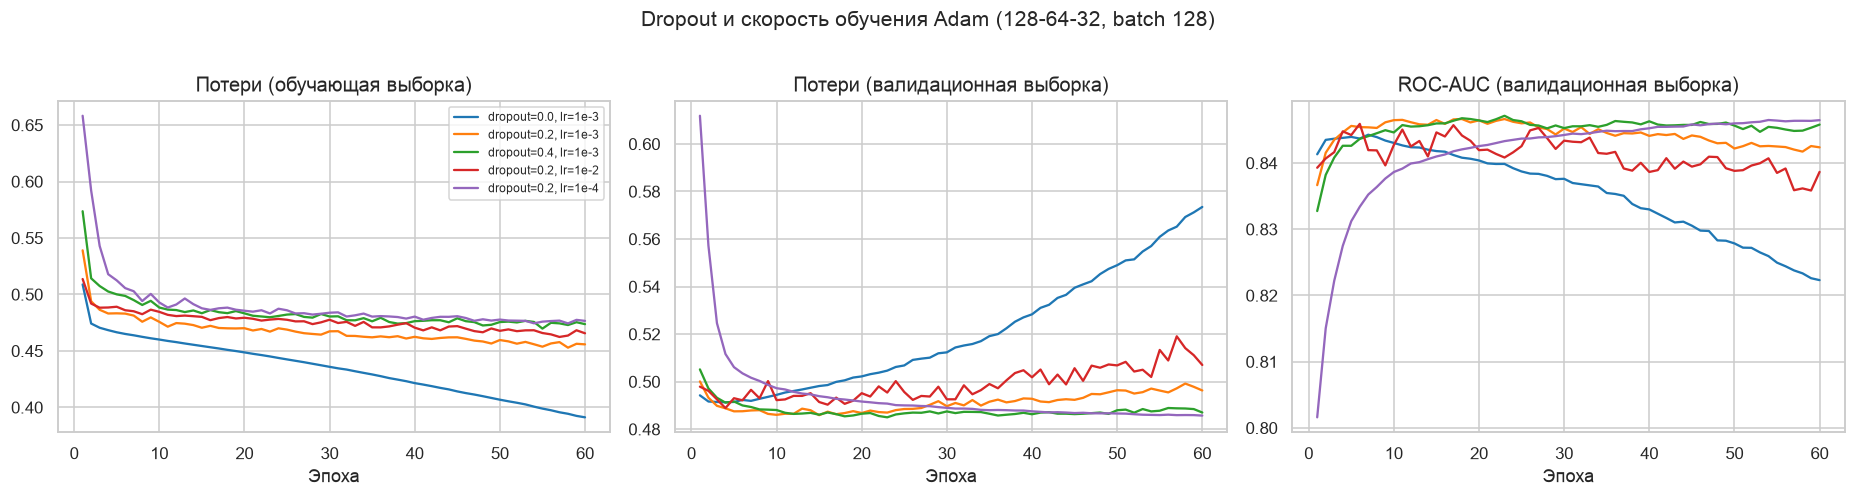

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,val_loss (финал),val_accuracy,val_AUC,"Время, с"
"dropout=0.0, lr=1e-3",60,12033,4,0.491300,0.573500,0.750200,0.822300,9.161900
"dropout=0.2, lr=1e-3",60,12033,15,0.485900,0.496300,0.765200,0.842400,10.089400
"dropout=0.4, lr=1e-3",60,12033,23,0.485000,0.487000,0.768700,0.845800,10.087000
"dropout=0.2, lr=1e-2",60,12033,4,0.488900,0.507000,0.767200,0.838700,10.110300
"dropout=0.2, lr=1e-4",60,12033,60,0.485700,0.485700,0.768200,0.846500,10.307700


In [25]:
for name, kw in {
    "dropout=0.0, lr=1e-3": dict(dropout=0.0, lr=1e-3),
    "dropout=0.2, lr=1e-3": dict(dropout=0.2, lr=1e-3),
    "dropout=0.4, lr=1e-3": dict(dropout=0.4, lr=1e-3),
    "dropout=0.2, lr=1e-2": dict(dropout=0.2, lr=1e-2),
    "dropout=0.2, lr=1e-4": dict(dropout=0.2, lr=1e-4),
}.items():
    run_experiment("5_regularization", name, hidden=(128, 64, 32), epochs=60, batch_size=128, **kw)
show_group("5_regularization", title="Dropout и скорость обучения Adam (128-64-32, batch 128)")

### Пояснение к исследованию прореживания и скорости обучения

Исследуется сеть 128-64-32 с функцией активации ReLU – наиболее склонная к переобучению конфигурация из предыдущих экспериментов.

- Прореживание (dropout) – случайное отключение заданной доли нейронов на каждом шаге обучения – непосредственно противодействует переобучению:
  - при доле 0.0 итоговый `val_loss` равен 0.574, минимум достигается на 4-й эпохе;
  - при доле 0.2 итоговый `val_loss` равен 0.496, минимум (0.486) достигается на 15-й эпохе;
  - при доле 0.4 итоговый `val_loss` равен 0.487, минимум (0.485) достигается на 23-й эпохе; это наилучший результат среди всех 24 экспериментальных запусков.

  Прореживание не только снижает переобучение, но и позволяет достичь меньшего минимума функции потерь: сеть вынуждена формировать устойчивые признаки, не зависящие от отдельных нейронов.
- Скорость обучения оптимизатора Adam (при доле прореживания 0.2):
  - при $10^{-2}$ шаг оптимизации слишком велик: минимум достигается на 4-й эпохе, затем `val_loss` возрастает до 0.507;
  - при $10^{-4}$ шаг мал: за 60 эпох переобучение не наступает, `val_loss` на последней эпохе равен 0.486, ROC-AUC на валидации – 0.847. Такой режим соответствует начальному этапу обучения со скоростью $10^{-3}$, растянутому в 10 раз.

Таким образом, прореживание оказалось наиболее эффективным средством повышения качества нейронной сети.

Пять лучших запусков по минимальному val_loss (из всех экспериментов):


Эксперимент,Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,val_loss (финал),val_accuracy,val_AUC,"Время, с"
5_regularization,"dropout=0.4, lr=1e-3",60,12033,23,0.485000,0.487000,0.768700,0.845800,10.087000
5_regularization,"dropout=0.2, lr=1e-4",60,12033,60,0.485700,0.485700,0.768200,0.846500,10.307700
5_regularization,"dropout=0.2, lr=1e-3",60,12033,15,0.485900,0.496300,0.765200,0.842400,10.089400
2_batch,batch=256,60,2945,10,0.488300,0.498400,0.766200,0.841000,6.330700
5_regularization,"dropout=0.2, lr=1e-2",60,12033,4,0.488900,0.507000,0.767200,0.838700,10.110300


Итоговая конфигурация: {'hidden': (128, 64, 32), 'activation': 'relu', 'dropout': 0.4, 'lr': 0.001, 'batch_size': 128}
Обучение остановлено на эпохе 38, восстановлены веса эпохи 23


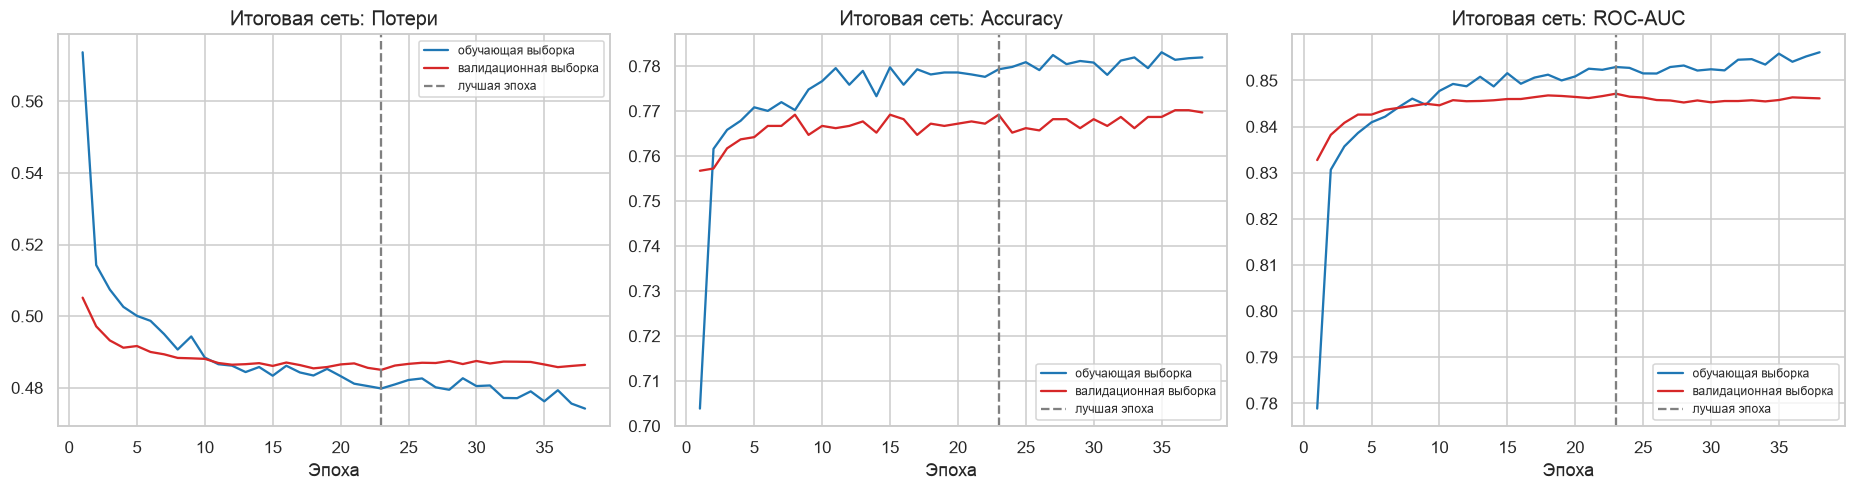

Метрики на тестовой выборке:


Модель,Accuracy,Precision,Recall,F1,ROC-AUC
"Базовая сеть 64-32, 200 эпох (переобученная)",0.768200,0.757200,0.789300,0.772900,0.840300
Нейронная сеть (TF),0.776500,0.775300,0.778600,0.776900,0.860300


In [26]:
runs_df = pd.DataFrame(nn_runs)
print("Пять лучших запусков по минимальному val_loss (из всех экспериментов):")
display(runs_df.sort_values("Мин. val_loss").head(5).drop(columns="config").round(4).style.hide(axis="index"))

# итоговая конфигурация = конфигурация лучшего запуска; число эпох выбирает EarlyStopping
FINAL = runs_df.sort_values("Мин. val_loss").iloc[0]["config"]
nn_final, hist_final = run_experiment("6_final", "final", epochs=300, early_stop=True, **FINAL)
print(f"Итоговая конфигурация: {FINAL}")
print(f"Обучение остановлено на эпохе {len(hist_final)}, восстановлены веса эпохи "
      f"{int(hist_final['val_loss'].idxmin())}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (tr_key, va_key, title) in zip(axes, [("loss", "val_loss", "Потери"),
                                             ("accuracy", "val_accuracy", "Accuracy"),
                                             ("auc", "val_auc", "ROC-AUC")]):
    ax.plot(hist_final.index, hist_final[tr_key], label="обучающая выборка", color="#1f77b4")
    ax.plot(hist_final.index, hist_final[va_key], label="валидационная выборка", color="#d62728")
    ax.axvline(int(hist_final["val_loss"].idxmin()), color="gray", linestyle="--", label="лучшая эпоха")
    ax.set_title(f"Итоговая сеть: {title}")
    ax.set_xlabel("Эпоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


class KerasWrapper:
    """Обёртка, чтобы сеть оценивалась той же функцией evaluate, что и sklearn-модели."""
    def __init__(self, m):
        self.m = m

    def predict_proba(self, X_):
        p = self.m.predict(np.asarray(X_, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X_):
        return (self.predict_proba(X_)[:, 1] >= 0.5).astype(int)


nn_wrapped = KerasWrapper(nn_final)
nn_metrics = evaluate(nn_wrapped, X_te_nn, "Нейронная сеть (TF)")
base_wrapped = KerasWrapper(model_long)
print("Метрики на тестовой выборке:")
display(pd.DataFrame([evaluate(base_wrapped, X_te_nn, "Базовая сеть 64-32, 200 эпох (переобученная)"),
                      nn_metrics]).round(4).style.hide(axis="index"))

### Пояснение к итоговой нейронной сети

Выбор конфигурации выполняется автоматически: из 24 экспериментальных запусков выбирается запуск с наименьшим значением `val_loss`. Им оказалась сеть 128-64-32 с функцией активации ReLU, долей прореживания 0.4, оптимизатором Adam (скорость обучения $10^{-3}$) и размером батча 128. Число эпох определяется ранней остановкой `EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)`: обучение прекращено на 38-й эпохе, восстановлены веса 23-й эпохи, на которой достигнут минимум `val_loss`.

Итоговая архитектура:

`Input(12) → Dense(128, ReLU) → Dropout(0.4) → Dense(64, ReLU) → Dropout(0.4) → Dense(32, ReLU) → Dropout(0.4) → Dense(1, sigmoid)`, 12 033 параметра.

Кривые обучения итоговой сети для обучающей и валидационной выборок близки и не расходятся существенно. В первые эпохи функция потерь на обучающей выборке даже превышает значение на валидационной, поскольку прореживание действует только при обучении. К моменту остановки различие невелико (0.474 против 0.486), а `val_loss` выходит на плато и не возрастает.

Результаты на тестовой выборке:

| Сеть | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Базовая 64-32, 200 эпох (переобученная) | 0.768 | 0.757 | 0.789 | 0.773 | 0.840 |
| Итоговая (прореживание и ранняя остановка) | 0.777 | 0.775 | 0.779 | 0.777 | 0.860 |

Регуляризация и ранняя остановка повысили ROC-AUC на тестовой выборке на 0.020, а Accuracy – почти на один процентный пункт. Значения Precision и Recall итоговой сети сбалансированы (0.775 и 0.779), что соответствует порогу 0.5 при сбалансированных классах.

In [27]:
import sys
os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]
%load_ext tensorboard
%tensorboard --logdir logs/fit --port 6006

Приведённая выше команда запускает TensorBoard непосредственно в ноутбуке: в Jupyter и VS Code отображается встроенная панель. Вне ноутбука тот же интерфейс запускается из терминала командой

```bash
.venv/bin/tensorboard --logdir logs/fit --port 6006
```

после чего доступен в браузере по адресу http://localhost:6006. На вкладке Scalars отображаются кривые `epoch_loss`, `epoch_accuracy` и `epoch_auc` для обучающей и валидационной выборок, на вкладках Histograms и Distributions – изменение распределений весов слоёв по эпохам. Фильтр запусков в левой панели позволяет сравнивать варианты одного эксперимента (например, все запуски `3_layers/*`).

Ниже те же скалярные метрики прочитаны непосредственно из файлов событий TensorBoard, что позволяет сохранить графики в отчёте.

Структура логов TensorBoard:
  logs/fit/1_epochs/: 200 эпох
  logs/fit/2_batch/: batch=128, batch=16, batch=256, batch=32, batch=512, batch=64
  logs/fit/3_layers/: 128-64-32, 256-128-64-32, 32, 512-256-128-64, 64-32, 8
  logs/fit/4_activation/: elu, relu, selu, sigmoid, swish, tanh
  logs/fit/5_regularization/: dropout=0.0, lr=1e-3, dropout=0.2, lr=1e-2, dropout=0.2, lr=1e-3, dropout=0.2, lr=1e-4, dropout=0.4, lr=1e-3
  logs/fit/6_final/: final


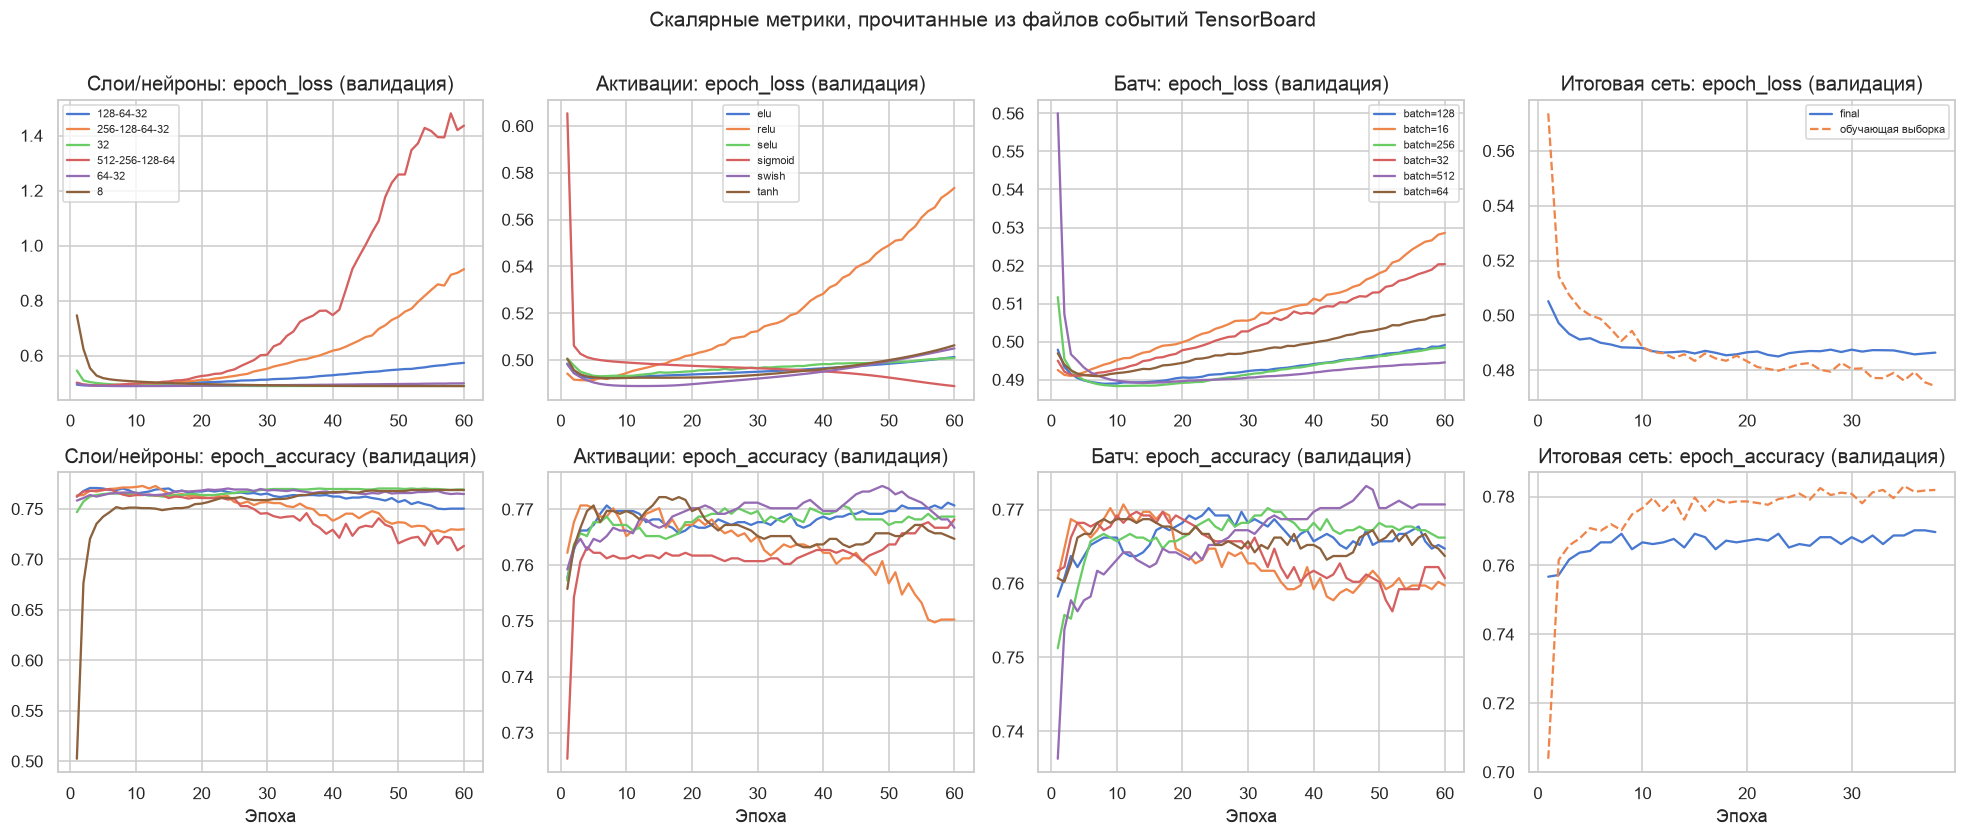

In [28]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def read_tb_scalars(run_dir):
    """Читает скаляры из event-файлов TensorBoard (папки train/ и validation/)."""
    out = {}
    for split in ["train", "validation"]:
        ea = EventAccumulator(os.path.join(run_dir, split), size_guidance={"tensors": 0})
        ea.Reload()
        for tag in ea.Tags()["tensors"]:
            if tag.startswith("epoch_"):
                vals = [(e.step + 1, float(tf.make_ndarray(e.tensor_proto))) for e in ea.Tensors(tag)]
                out[(split, tag)] = pd.Series(dict(vals))
    return out


groups = sorted(d for d in os.listdir(LOG_ROOT) if not d.startswith("."))
print("Структура логов TensorBoard:")
for g in groups:
    print(f"  {LOG_ROOT}/{g}/: " + ", ".join(sorted(os.listdir(f"{LOG_ROOT}/{g}"))))

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for col, (g, title) in enumerate([("3_layers", "Слои/нейроны"), ("4_activation", "Активации"),
                                  ("2_batch", "Батч"), ("6_final", "Итоговая сеть")]):
    for run in sorted(os.listdir(f"{LOG_ROOT}/{g}")):
        sc = read_tb_scalars(f"{LOG_ROOT}/{g}/{run}")
        axes[0, col].plot(sc[("validation", "epoch_loss")], label=run)
        axes[1, col].plot(sc[("validation", "epoch_accuracy")], label=run)
        if g == "6_final":
            axes[0, col].plot(sc[("train", "epoch_loss")], "--", label="обучающая выборка")
            axes[1, col].plot(sc[("train", "epoch_accuracy")], "--", label="обучающая выборка")
    axes[0, col].set_title(f"{title}: epoch_loss (валидация)")
    axes[1, col].set_title(f"{title}: epoch_accuracy (валидация)")
    axes[1, col].set_xlabel("Эпоха")
    axes[0, col].legend(fontsize=7)
plt.suptitle("Скалярные метрики, прочитанные из файлов событий TensorBoard", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### Пояснение к логам TensorBoard

Логи организованы по экспериментам: `logs/fit/<эксперимент>/<вариант>/{train, validation}`. Такая структура позволяет в TensorBoard выбирать и сравнивать группы запусков с помощью регулярного выражения в фильтре (например, `3_layers` или `4_activation`).

На приведённых графиках показаны те же кривые, что и в интерфейсе TensorBoard; скалярные метрики `epoch_loss` и `epoch_accuracy` прочитаны из файлов событий с помощью `EventAccumulator`:

- Число слоёв: у сетей 512-256-128-64 и 256-128-64-32 функция потерь на валидации возрастает до 1.4 и 0.9 соответственно, тогда как у малых сетей (8, 32, 64-32) она остаётся на уровне около 0.49.
- Функции активации: при использовании ReLU `val_loss` возрастает быстрее всего; при использовании sigmoid обучение начинается с большого значения функции потерь, которое затем медленно убывает.
- Размер батча: чем меньше батч, тем раньше и быстрее возрастает функция потерь на валидации.
- Итоговая сеть: функция потерь на валидации выходит на плато около 0.486 и не возрастает; значения accuracy на обучающей и валидационной выборках близки (0.77–0.78), что свидетельствует об отсутствии переобучения.

### Снимки интерфейса TensorBoard

Снимки получены при запущенной команде `tensorboard --logdir logs/fit` (вкладка Time Series, коэффициент сглаживания 0.6).

Эксперимент с числом слоёв и нейронов (фильтр запусков `3_layers`, метрика `epoch_loss`). Для крупных сетей хорошо заметно расхождение кривых для обучающей и валидационной выборок:

![TensorBoard: число слоёв и нейронов](images/tb_scalars_layers.png)

Итоговая сеть (фильтр `6_final`): метрики `epoch_accuracy`, `epoch_auc`, `epoch_learning_rate` и `epoch_loss` для обучающей и валидационной выборок; обучение остановлено `EarlyStopping` на 38-й эпохе:

![TensorBoard: итоговая сеть](images/tb_scalars_final.png)

Функции активации (фильтр `4_activation`, метрика `epoch_auc`):

![TensorBoard: функции активации](images/tb_scalars_activation.png)

Гистограммы весов (`kernel`) четырёх слоёв `Dense` итоговой сети по эпохам (`histogram_freq=1`). Распределения весов постепенно расширяются относительно начальной инициализации Глоро и затем стабилизируются; это свидетельствует о том, что обучение протекает без неограниченного роста или затухания весов:

![TensorBoard: гистограммы весов](images/tb_histograms_final.png)

## 7. Сравнительный анализ

ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТОВОЙ ВЫБОРКЕ (настроенные модели)


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Наивный Байес,0.738000,0.872500,0.557200,0.680100,0.841700
Дерево решений,0.770300,0.788500,0.738500,0.762700,0.847200
LDA,0.764600,0.789300,0.721700,0.754000,0.847300
SVM,0.777700,0.786400,0.762400,0.774200,0.855700
kNN,0.763700,0.796200,0.708600,0.749800,0.854500
Нейронная сеть (TF),0.776500,0.775300,0.778600,0.776900,0.860300


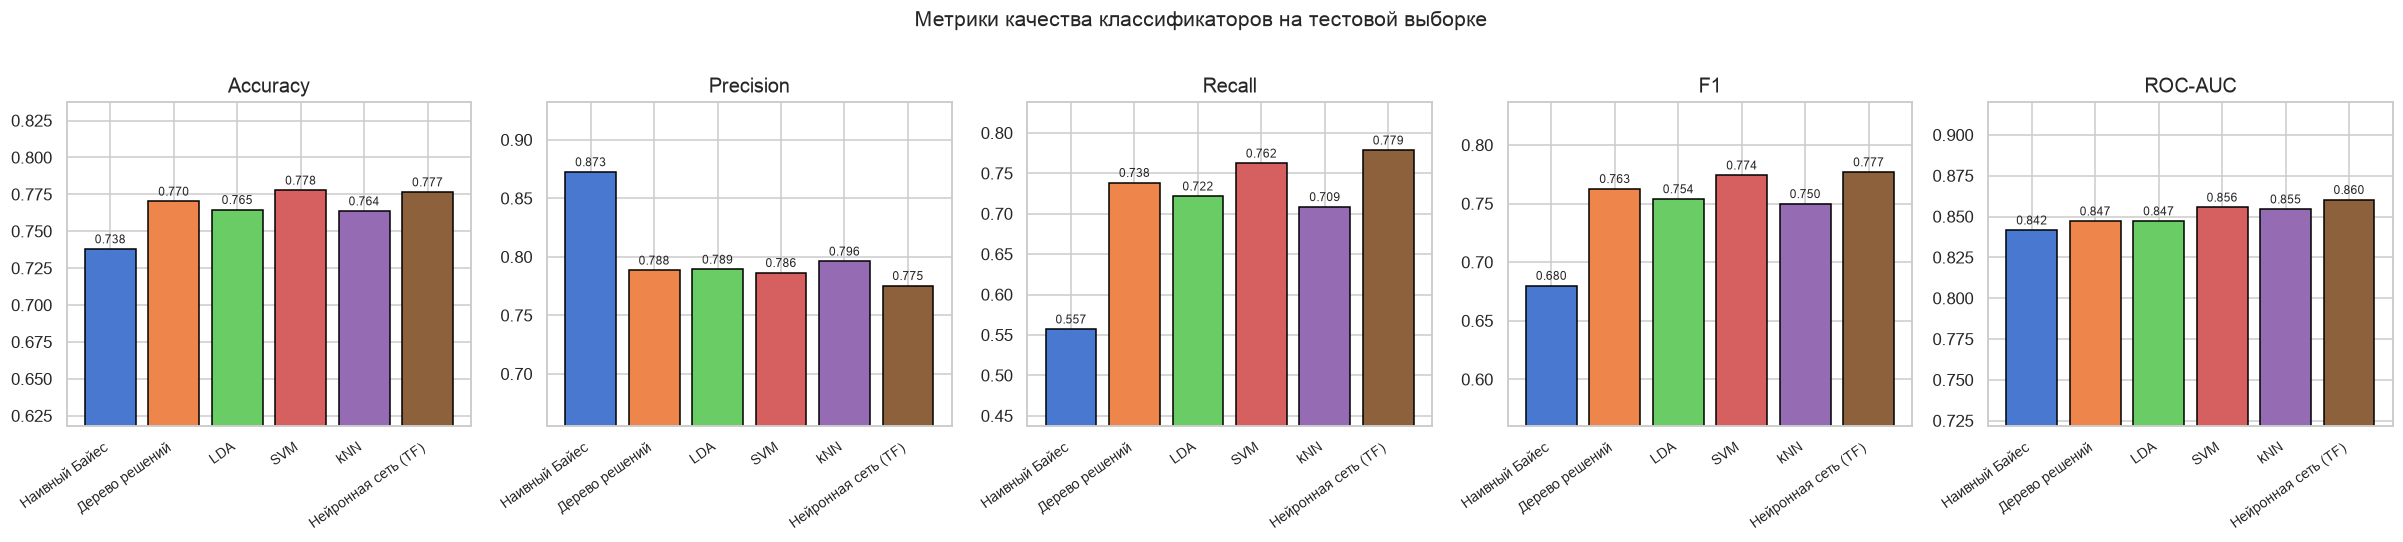

In [29]:
final_df = pd.DataFrame(results_tuned + [nn_metrics]).set_index("Модель")
print("ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТОВОЙ ВЫБОРКЕ (настроенные модели)")
display(final_df.round(4).style.highlight_max(axis=0, color="#c7e9c0"))

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
palette = sns.color_palette("muted", len(final_df))
for ax, m in zip(axes, metrics):
    bars = ax.bar(range(len(final_df)), final_df[m], color=palette, edgecolor="black")
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xticks(range(len(final_df)))
    ax.set_xticklabels(final_df.index, rotation=35, ha="right", fontsize=9)
    ax.set_ylim(max(0, final_df[m].min() - 0.12), min(1.0, final_df[m].max() + 0.06))
    ax.set_title(m)
plt.suptitle("Метрики качества классификаторов на тестовой выборке", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Пояснение к сравнительной таблице

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Наивный байесовский классификатор (GaussianNB) | 0.738 | **0.873** | 0.557 | 0.680 | 0.842 |
| Дерево решений | 0.770 | 0.789 | 0.739 | 0.763 | 0.847 |
| LDA | 0.765 | 0.789 | 0.722 | 0.754 | 0.847 |
| SVM (RBF-ядро) | **0.778** | 0.786 | 0.762 | 0.774 | 0.856 |
| kNN | 0.764 | 0.796 | 0.709 | 0.750 | 0.855 |
| Нейронная сеть (TensorFlow) | 0.777 | 0.775 | **0.779** | **0.777** | **0.860** |

- По ROC-AUC модели образуют две группы: нейронная сеть, SVM и kNN (0.855–0.860) и LDA, дерево решений, наивный байесовский классификатор (0.842–0.847). Разница между лучшей и худшей моделью составляет лишь 0.018: качество всех методов ограничено информативностью имеющихся признаков.
- По Accuracy SVM (0.7777) и нейронная сеть (0.7765) практически равны: различие соответствует 4 заёмщикам из 3 343.
- Precision формально максимален у наивного байесовского классификатора (0.87), однако ценой Recall 0.56: модель не выявляет 44% заёмщиков с дефолтом, что неприемлемо для задачи кредитного скоринга.
- Recall и F1 максимальны у нейронной сети: она выявляет 78% заёмщиков с дефолтом при Precision 0.78.

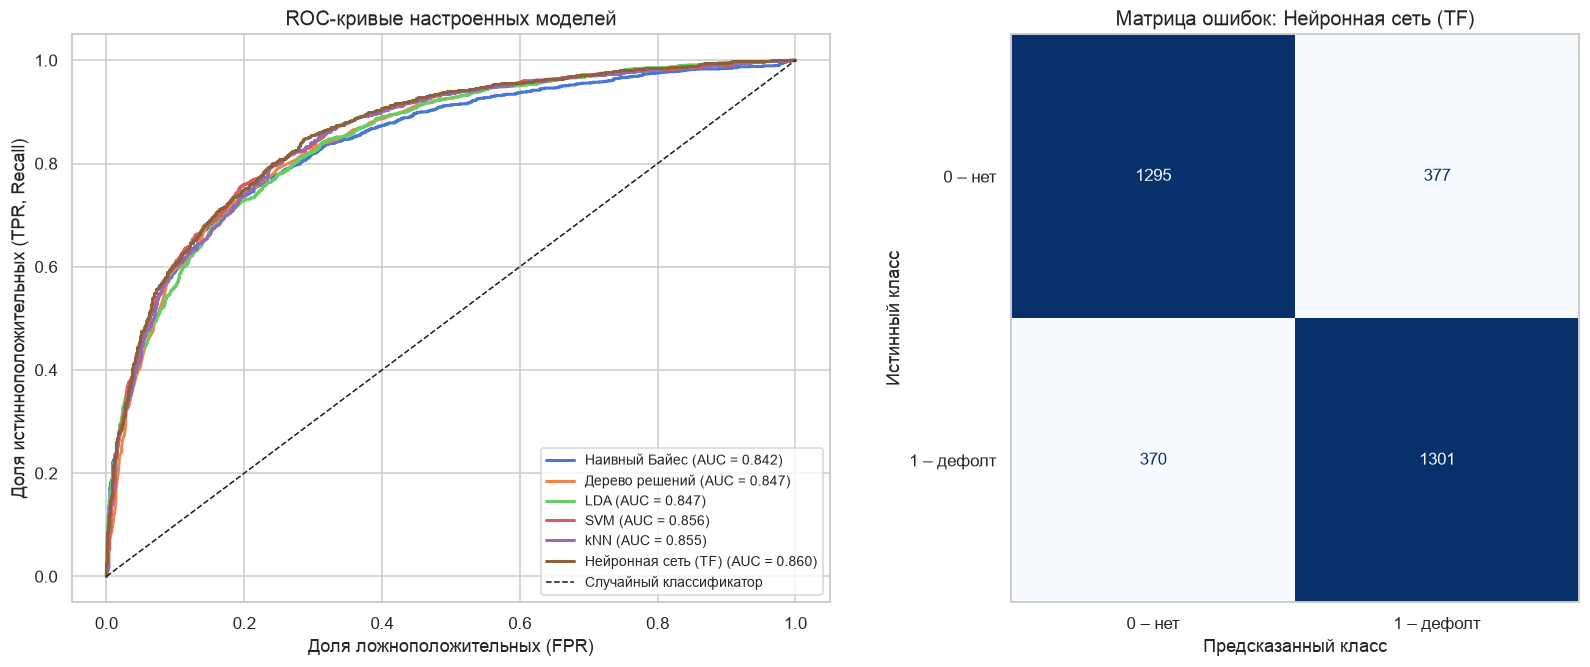

Средний ранг модели по пяти метрикам (1 – лучший):


,Средний ранг
Модель,
Нейронная сеть (TF),2.2
SVM,2.4
Дерево решений,3.6
LDA,3.8
kNN,4.0
Наивный Байес,5.0


In [30]:
all_for_roc = dict(tuned_models)
all_for_roc["Нейронная сеть (TF)"] = (nn_wrapped, X_te_nn)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})
for (name, (model, Xte)), c in zip(all_for_roc.items(), palette):
    s = get_scores(model, Xte)
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=c, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Случайный классификатор")
axes[0].set_xlabel("Доля ложноположительных (FPR)")
axes[0].set_ylabel("Доля истинноположительных (TPR, Recall)")
axes[0].set_title("ROC-кривые настроенных моделей")
axes[0].legend(fontsize=9, loc="lower right")

best_name = final_df["ROC-AUC"].idxmax()
best_model, best_X = all_for_roc[best_name]
cm = confusion_matrix(y_test, best_model.predict(best_X))
ConfusionMatrixDisplay(cm, display_labels=["0 – нет", "1 – дефолт"]).plot(ax=axes[1], cmap="Blues",
                                                                          colorbar=False, values_format="d")
axes[1].set_title(f"Матрица ошибок: {best_name}")
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")
axes[1].grid(False)
plt.tight_layout()
plt.show()

rank = final_df.rank(ascending=False).mean(axis=1).sort_values()
print("Средний ранг модели по пяти метрикам (1 – лучший):")
display(rank.round(2).rename("Средний ранг").to_frame())

### Пояснение к ROC-кривым и выбору модели

ROC-кривые всех моделей практически совпадают; заметно ниже остальных располагается лишь кривая наивного байесовского классификатора в диапазоне FPR от 0.4 до 0.8. При FPR = 0.2 (ошибочный отказ 20% надёжных клиентов) лучшие модели выявляют около 76% заёмщиков с дефолтом.

Матрица ошибок нейронной сети на 3 343 тестовых наблюдениях: верно выявлено 1 301 заёмщик с дефолтом, пропущено 370 (FN); 377 надёжных заёмщиков ошибочно отнесены к рискованным (FP), 1 295 классифицированы верно. Число ошибок обоих типов практически одинаково, то есть модель не смещена в пользу какого-либо класса.

Средний ранг по пяти метрикам: нейронная сеть – 2.2, SVM – 2.4, дерево решений – 3.6, LDA – 3.8, kNN – 4.0, наивный байесовский классификатор – 5.0.

**Выбор наилучшего подхода.** Наилучшее качество на рассматриваемом наборе данных обеспечивает нейронная сеть с прореживанием и ранней остановкой (ROC-AUC 0.860, F1 0.777). Близкий результат показывает SVM с RBF-ядром (ROC-AUC 0.856, наибольшая Accuracy 0.778). Преимущество нейронной сети невелико (+0.005 по ROC-AUC), поэтому выбор модели определяется требованиями прикладной задачи:

- если приоритетом является максимальное качество прогноза и оценка вероятности риска, целесообразно использовать нейронную сеть;
- если важны простота и интерпретируемость (в кредитном скоринге решение об отказе, как правило, требуется обосновывать), предпочтительны LDA или дерево решений: они уступают лучшей модели лишь 0.013 по ROC-AUC, но позволяют получить явные коэффициенты и правила.

Малый разрыв между простыми и сложными моделями показывает, что качество ограничено информативностью данных, а не выбором метода. Дальнейшее повышение качества возможно скорее за счёт новых признаков (история платежей, кредитный рейтинг), чем за счёт усложнения модели.

## 8. Заключение

1. Для исследования методов классификации выбран набор данных Credit Risk Benchmark Dataset: 16 714 заёмщиков, 10 финансовых признаков, бинарная целевая переменная – серьёзная просрочка в течение двух лет. Классы сбалансированы в соотношении 50/50.
2. Предобработка данных оказала решающее влияние на качество. Служебные коды 96/98 заменены медианой с сохранением признака-индикатора (среди таких наблюдений 94% дефолтов), выбросы ограничены по 99-му перцентилю, признаки с сильной асимметрией логарифмированы, все признаки стандартизованы. Параметры преобразований вычислены только по обучающей выборке. Без предобработки ROC-AUC наивного байесовского классификатора снижается с 0.84 до 0.71, метода kNN – с 0.85 до 0.76.
3. Выборка разделена в соотношении 80/20 со стратификацией. Гиперпараметры подбирались пятикратной стратифицированной кросс-валидацией по критерию ROC-AUC; тестовая выборка использовалась только для итоговой оценки. Все эксперименты воспроизводимы (`SEED = 42`).
4. Настройка гиперпараметров в наибольшей степени повысила качество гибких методов: дерева решений (+0.161 по ROC-AUC за счёт ограничения сложности: глубина 10, не менее 80 объектов в листе) и kNN (+0.044 при $k = 101$). Для SVM прирост составил +0.010 ($C = 0.3$, $\gamma = 0.02$, то есть гладкая граница). Качество наивного байесовского классификатора и LDA практически не изменилось.
5. Нейронная сеть на TensorFlow: исследовано влияние числа эпох, размера батча, архитектуры (от 113 до 179 тыс. параметров), шести функций активации, прореживания и скорости обучения; все 25 запусков записаны в логи TensorBoard. Установлено, что сеть быстро переобучается (минимум `val_loss` достигается за 4–10 эпох), увеличение размера сети не повышает качество, а наилучший результат обеспечивают прореживание с долей 0.4 и ранняя остановка.
6. По результатам сравнения наилучшей моделью признана нейронная сеть 128-64-32 с функцией активации ReLU и прореживанием 0.4 (Accuracy 0.777, Precision 0.775, Recall 0.779, F1 0.777, ROC-AUC 0.860); близкий результат показал SVM (ROC-AUC 0.856, Accuracy 0.778). Разброс ROC-AUC между всеми моделями составляет лишь 0.018, что указывает на ограничение качества информативностью признаков.

## Список источников

1. Scikit-learn: Supervised learning [Электронный ресурс]. – URL: https://scikit-learn.org/stable/supervised_learning.html
2. TensorFlow: Keras API [Электронный ресурс]. – URL: https://www.tensorflow.org/api_docs/python/tf/keras
3. TensorBoard: Get started [Электронный ресурс]. – URL: https://www.tensorflow.org/tensorboard/get_started
4. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. – 2nd ed. – Springer, 2009.
5. Goodfellow I., Bengio Y., Courville A. Deep Learning. – MIT Press, 2016.
6. Credit Risk Benchmark Dataset [Электронный ресурс] // Kaggle. – URL: https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset